# From Words to Numbers: Pseudo-quantification and the Quantification of Uncertainty

**Social Science Simulations (SVUH.00.300) · Seminar: Transforming qualitative social science variables into machine-readable form**
ACHARYA Kishor · Institute of Social Studies, University of Tartu · Autumn 2026

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ACHARYAkishor/Monte_carlo_Seminar_UniTartu/blob/main/Words_to_Numbers_UniTartu_ACHARYA.ipynb)  ·  [Slides and data on GitHub](https://github.com/ACHARYAkishor/Monte_carlo_Seminar_UniTartu)

---

## How to use this notebook

This notebook follows the seminar stop by stop, with the same numbering as the slides. It continues directly from the Monte Carlo seminar: there we took every input number for granted (“polls miss by 3 points”, “a household wants 30%”); here we ask where such numbers come from, how to make them from the words, scales and judgements that social research actually produces, and how to carry our doubt about that translation honestly into a model.

Every stop has a plain-words explanation, a code cell with line-by-line comments, a **▶ Try it** cell with sliders, and a box called **Where is the translation recipe here?**. You can follow the whole seminar without reading the code.

Three sources of data run through the notebook:

1. **The World Values Survey for Estonia**, 1996 and 2011: published answers of about 1,000 and 1,500 Estonians to “is it justifiable to avoid a fare on public transport?” (1 = never, 10 = always), with two companion items (cheating on taxes, accepting a bribe). Real data, cited in the file `wvs_estonia_justifiable.csv`.
2. **The class questionnaire**: your own twelve answers from before the seminar, in `class_responses.csv`. If fewer than 15 of you answered, the notebook draws a synthetic class from the WVS distributions and says so.
3. **The models from the Monte Carlo seminar**: Schelling's city and Granovetter's crowd, unchanged except for one line.

> **First step:** run the setup cell below. It loads the tools, the WVS data and the class data.

In [1]:
# ---- Setup: run this cell first ------------------------------------------
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown, Checkbox
import os, io, urllib.request

TEAL, DARK, CORAL, GRAY, AMBER, GREEN = "#008080", "#0A5C5C", "#D85A30", "#888780", "#C97B3A", "#1D9E75"
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(seed=2026)

REPO = "https://raw.githubusercontent.com/ACHARYAkishor/Monte_carlo_Seminar_UniTartu/main/"

def load_csv(name, required=True):
    '''Load a CSV from the folder next to this notebook if it is there, otherwise from GitHub.'''
    if os.path.exists(name):
        return pd.read_csv(name)
    try:
        with urllib.request.urlopen(REPO + name, timeout=20) as r:
            return pd.read_csv(io.StringIO(r.read().decode("utf-8")))
    except Exception as e:
        if required:
            raise FileNotFoundError(f"{name} not found locally or at {REPO}{name}") from e
        return None

wvs = load_csv("wvs_estonia_justifiable.csv")
SCALE_COLS = ["v1_never", "v2", "v3", "v4", "v5", "v6", "v7", "v8", "v9", "v10_always"]
print("WVS data loaded:", len(wvs), "distributions")
print(wvs[["item", "year", "variable", "n_valid"]].to_string(index=False))

# A test slider: if you see a slider below, the interactive cells will work.
from IPython.display import display
display(IntSlider(value=3, description="test slider"))

WVS data loaded: 6 distributions
           item  year variable  n_valid
  avoiding_fare  1996     V193      993
 cheating_taxes  1996     V194      986
accepting_bribe  1996     V196     1004
  avoiding_fare  2011     V199     1503
 cheating_taxes  2011     V201     1500
accepting_bribe  2011     V202     1514


IntSlider(value=3, description='test slider')

### Loading the class questionnaire

The form exports one row per student with the question text as column headers. The cell below recognises each question by a phrase from its text, renames it to a short code, and cleans the numbers. If the file is missing or has fewer than 15 rows, it builds a **synthetic class** instead: 29 imaginary students whose answers are drawn from the WVS distributions and from plausible spreads for the other items. Whenever that happens the notebook says `SYNTHETIC` in its titles, so nobody mistakes invented answers for real ones.

In [2]:
CODES = {   # phrase in the question text  ->  short code
    "Think of 10 passengers":   "emp_exp",
    "10 Tartu residents":       "norm_exp",
    "can be justified":         "justif",
    "At what number would you": "thr_fare",
    "never do it":              "thr_fare_never",
    "eight households":         "thr_nbr",
    "most of my neighbours":    "likert_nbr",
    "cups of coffee":           "coffee",
    "movie nights":             "thr_movie",
    "never say anything":       "thr_movie_never",
    "messaging app":            "thr_app",
    "trust the Tartu bus":      "trust_tt",
    "In one sentence":          "trust_why",
    "How often do you use":     "bus_use",
}
NUMERIC = ["emp_exp", "norm_exp", "justif", "thr_fare", "thr_nbr", "likert_nbr", "coffee", "thr_movie", "thr_app", "trust_tt"]

def tidy_class(raw):
    '''Rename form columns to codes, turn checkboxes into True/False, numbers into numbers.'''
    out = pd.DataFrame()
    for col in raw.columns:
        for phrase, code in CODES.items():
            if phrase.lower() in str(col).lower():
                out[code] = raw[col]
    for c in ["thr_fare_never", "thr_movie_never"]:
        out[c] = out[c].notna() & (out[c].astype(str).str.strip() != "") if c in out else False
    for c in NUMERIC:
        if c in out:
            out[c] = pd.to_numeric(out[c].astype(str).str.extract(r"(-?\d+\.?\d*)")[0], errors="coerce")
    return out

def synthetic_class(n=29, seed=7):
    '''An imaginary class, used only when the real answers are missing. Drawn from WVS 2011 where possible.'''
    r = np.random.default_rng(seed)
    fare2011 = wvs[(wvs.item == "avoiding_fare") & (wvs.year == 2011)][SCALE_COLS].values[0]
    justif = r.choice(np.arange(1, 11), size=n, p=fare2011 / fare2011.sum())
    thr_fare = np.clip(np.round(10 - justif + r.normal(0, 1.2, n)), 0, 10)
    never = justif == 1
    thr_nbr = np.clip(np.round(r.normal(3.0, 1.6, n)), 0, 8)
    likert = np.clip(np.round(1 + thr_nbr / 8 * 4 + r.normal(0, 0.7, n)), 1, 5)
    why = r.choice(["Usually on time in my experience", "Buses are often late in winter", "I don't use the bus much",
                    "The app shows real-time positions", "Timetable fine, traffic is the problem", "Never checked it",
                    "Sometimes the bus leaves early", "Reliable on main lines, not in suburbs"], size=n)
    return pd.DataFrame({
        "emp_exp": np.clip(np.round(r.normal(2.5, 1.5, n)), 0, 10), "norm_exp": np.clip(np.round(r.normal(6, 2, n)), 0, 10),
        "justif": justif, "thr_fare": thr_fare, "thr_fare_never": never,
        "thr_nbr": thr_nbr, "likert_nbr": likert, "coffee": np.clip(np.round(r.normal(2.2, 1.3, n)), 0, 8),
        "thr_movie": np.clip(np.round(r.normal(3, 2, n)), 0, 10), "thr_movie_never": r.random(n) < 0.15,
        "thr_app": np.clip(np.round(r.normal(4, 2.2, n)), 0, 10), "trust_tt": np.clip(np.round(r.normal(3.6, 0.9, n)), 1, 5),
        "trust_why": why, "bus_use": r.choice(["Never", "A few times a year", "Monthly", "Weekly", "Daily"], size=n, p=[.1, .2, .2, .3, .2]),
    })

raw = load_csv("class_responses.csv", required=False)
if raw is not None and len(raw) >= 15:
    cls = tidy_class(raw); CLASS_LABEL = f"class, n = {len(cls)}"
    print(f"Class data loaded: {len(cls)} responses.")
else:
    cls = synthetic_class(); CLASS_LABEL = "SYNTHETIC class, n = 29"
    print("No class file with at least 15 rows found: using a SYNTHETIC class drawn from WVS 2011. Titles will say so.")
cls.head()

No class file with at least 15 rows found: using a SYNTHETIC class drawn from WVS 2011. Titles will say so.


,emp_exp,norm_exp,justif,thr_fare,thr_fare_never,thr_nbr,likert_nbr,coffee,thr_movie,thr_movie_never,thr_app,trust_tt,trust_why,bus_use
0,4.0,4.0,3,7.0,False,5.0,3.0,1.0,1.0,False,6.0,3.0,Never checked it,Never
1,3.0,7.0,6,2.0,False,2.0,3.0,0.0,0.0,False,5.0,5.0,Buses are often late in winter,Monthly
2,0.0,9.0,5,4.0,False,3.0,3.0,3.0,3.0,False,0.0,4.0,Sometimes the bus leaves early,Monthly
3,4.0,3.0,1,8.0,True,2.0,2.0,3.0,1.0,False,5.0,4.0,The app shows real-time positions,Weekly
4,5.0,6.0,1,8.0,True,3.0,3.0,2.0,0.0,False,4.0,3.0,Sometimes the bus leaves early,Monthly


# Part A · Where the last seminar left us

The Monte Carlo recipe never changed across six stops: a *model* with something uncertain in it, a *random draw* from a distribution for each uncertain thing, *repeat and count*. What changed was what sat inside the model. But at every stop the distributions came from nowhere in particular: we *said* polls miss by three points; we *said* a household wants 30% similar neighbours. The closing question of that seminar was: where did 30% come from?

This seminar answers it. A simulation consumes numbers; social research produces words, scales, categories and judgements. The step between them has two parts:

* **Pseudo-quantification**: turning qualitative material into numbers a model can use. “Pseudo” because the number is not measured the way a length is measured; it is *assigned*, by a rule we choose, and a different rule would give a different number.
* **Quantification of uncertainty**: writing down how sure we are of that assignment, as a distribution, so that the Monte Carlo loop can carry the doubt through the model instead of hiding it.

The payoff, at Stop 5, is not only honesty. Once the inputs are distributions *across people* rather than single numbers, the model starts doing things nobody put in: tipping points, cascades, segregation from mild preferences. Heterogeneity is where emergence comes from, and averaging it away is what kills it.

> **One sentence for the seminar:** every number in a social simulation is a translation of something qualitative, every translation is a choice, and the choice must be written down as a distribution.

## The translation recipe

The Monte Carlo seminar had one recipe (model, random draw, repeat and count) and asked at every stop where it was. This seminar has one too, and we will ask the same question. Every number in a social simulation is made in four steps:

1. **The material**: what research gave you. A category, an ordered scale, a count, a sentence, an expert's judgement.
2. **The rule**: the stated procedure that turns the material into a number. A mapping from a scale, a codebook for text, an elicitation protocol for judgement. It is always a choice, and it is always written down.
3. **The distribution**: what the rule produces, across people and across our doubt about the rule. Never a single number.
4. **The use**: which of the four inputs of a model it becomes: an agent attribute, a rule, a parameter, or part of the initial state.

Between steps 3 and 4 sits the question this seminar keeps asking: **what uncertainty is carried forward** into the model from this translation? Each stop ends with a box that names the four steps and the uncertainty for that stop's experiment.

# Stop 1 · The gap: what a simulation needs, what research gives

## 1.1 Four kinds of number a simulation needs

Look back at the Schelling code from the Monte Carlo seminar. Every number in it is one of four kinds:

| Kind | In Schelling's city | In Granovetter's crowd | In the referendum |
|---|---|---|---|
| **Agent attributes** | each household's threshold, its kind | each person's threshold | — |
| **Rules** | “move if below threshold, to a random empty house” | “join once the share of others reaches my threshold” | “passes if yes > 50%” |
| **Parameters** | grid size, share of empty houses | crowd size | poll SD 3, turnout mean −1 |
| **Initial state** | the random starting arrangement | nobody has joined | polled share 52% |

Rules are usually written in words first and then as `if` statements; attributes and parameters are numbers; the initial state is a mix. Pseudo-quantification is mostly about the attributes and the parameters, but a rule can hide a number too (“most of my neighbours” is a rule with a threshold in it).

## 1.2 Five kinds of material social research gives

Statisticians sort measurements by what the numbers *mean* (Stevens, 1946): by which operations on them make sense. The sorting tells you how much translation each kind needs.

| Level | What it means | Operations that make sense | Examples | Translation needed |
|---|---|---|---|---|
| **Nominal** | labels; order means nothing | count, mode, "same or different" | occupation; bus user / non-user; religion | code to indicators; never do arithmetic on the codes |
| **Ordinal** | a meaningful order, but unknown or unequal distances | rank, median, "more or less" | race positions; Likert items; "never … always" 1–10 | the whole problem of Stop 2 |
| **Interval** | equal distances, arbitrary zero | add, subtract, mean | temperature in °C; a calendar year | little |
| **Ratio** | equal distances and a true zero | multiply, divide, ratios | cups of coffee; income; neighbours out of eight | none |
| **Not a number** | a sentence, a judgement, a relation | none until coded | an interview answer; an expert's guess; who talks to whom | Stop 3 |

The class questionnaire was built to contain each kind once. The cell below shows it as a catalogue.

In [3]:
catalogue = pd.DataFrame([
    ["Q1", "emp_exp",   "How many of 10 passengers travel without a ticket?",          "count 0–10 (a belief)",   "empirical expectation",      "attribute"],
    ["Q2", "norm_exp",  "How many of 10 residents would disapprove?",                   "count 0–10 (a belief)",   "normative expectation",      "attribute"],
    ["Q3", "justif",    "Is travelling without a ticket justifiable? 1–10",             "ORDINAL scale",           "personal normative belief",  "attribute (needs mapping)"],
    ["Q4", "thr_fare",  "At how many of 10 dodgers would you dodge?",                   "threshold 0–10 (+ never)","conditional preference",     "attribute (direct)"],
    ["Q5", "thr_nbr",   "How many of 8 neighbours should be like you?",                 "threshold 0–8",           "Schelling threshold",        "attribute (direct)"],
    ["Q6", "likert_nbr","Uncomfortable if most neighbours different (1–5)",             "ORDINAL scale",           "same attitude as Q5",        "attribute (needs mapping)"],
    ["Q7", "coffee",    "Cups of coffee per day",                                       "RATIO",                   "control: a true number",     "—"],
    ["Q8", "thr_movie", "Loud movie nights per month before complaining",               "threshold 0–10 (+ never)","a threshold, trivial domain", "attribute (direct)"],
    ["Q9", "thr_app",   "Friends out of 10 before adopting an app",                     "threshold 0–10",          "Granovetter threshold",      "attribute (direct)"],
    ["Q10","trust_tt",  "Trust in the bus timetable (1–5)",                             "ORDINAL scale",           "attitude, no behavioural anchor", "attribute (hard mapping)"],
    ["Q11","trust_why", "In one sentence: why?",                                        "TEXT",                    "qualitative material",       "Stop 3"],
    ["Q12","bus_use",   "How often do you use a bus or Smart Bike?",                    "ORDERED CATEGORY",        "a grouping variable",        "rule / sub-population"],
], columns=["Q", "code", "question", "level of measurement", "what it is in the theory", "simulation input"])
catalogue

,Q,code,question,level of measurement,what it is in the theory,simulation input
0,Q1,emp_exp,How many of 10 passengers travel without a tic...,count 0–10 (a belief),empirical expectation,attribute
1,Q2,norm_exp,How many of 10 residents would disapprove?,count 0–10 (a belief),normative expectation,attribute
2,Q3,justif,Is travelling without a ticket justifiable? 1–10,ORDINAL scale,personal normative belief,attribute (needs mapping)
3,Q4,thr_fare,At how many of 10 dodgers would you dodge?,threshold 0–10 (+ never),conditional preference,attribute (direct)
4,Q5,thr_nbr,How many of 8 neighbours should be like you?,threshold 0–8,Schelling threshold,attribute (direct)
5,Q6,likert_nbr,Uncomfortable if most neighbours different (1–5),ORDINAL scale,same attitude as Q5,attribute (needs mapping)
6,Q7,coffee,Cups of coffee per day,RATIO,control: a true number,—
7,Q8,thr_movie,Loud movie nights per month before complaining,threshold 0–10 (+ never),"a threshold, trivial domain",attribute (direct)
8,Q9,thr_app,Friends out of 10 before adopting an app,threshold 0–10,Granovetter threshold,attribute (direct)
9,Q10,trust_tt,Trust in the bus timetable (1–5),ORDINAL scale,"attitude, no behavioural anchor",attribute (hard mapping)


## 1.3 The chain: concept → indicator → variable → parameter

Between a sociological concept and a number in a model there are three steps (Lazarsfeld, 1958, called the path *operationalisation*), and each is a place where a researcher makes a choice. Followed through for our case:

| Link | What it is | The researcher's choice | For fare dodging |
|---|---|---|---|
| **Concept** | an abstract idea that cannot be observed directly | which theory of the concept to adopt | "fare dodging is a social norm" (Bicchieri) |
| **Indicator** | something observable that stands for the concept | which observable things count as evidence | what people believe others do and approve of; what they would do themselves |
| **Variable** | the indicator measured, with a scale | which question, which scale, which units | Q1–Q4: counts out of 10, a 1–10 scale, a tick-box |
| **Parameter or attribute** | the variable turned into what the model consumes | which rule turns the scale into the number (Stop 2) | each agent's threshold, between 0 and 1 |

For social norms there is a theory that makes the chain concrete. Bicchieri (2017) defines a social norm as a behaviour that people prefer to follow **on condition that** (a) they believe enough others follow it (*empirical expectations*) and (b) they believe enough others think they should (*normative expectations*). A habit or a moral conviction, by contrast, does not depend on others. The questionnaire measures each part: Q1 is the empirical expectation, Q2 the normative expectation, Q3 the personal belief, and Q4 the conditional preference, which is the threshold itself.

The cell below draws the class's answers to those four questions. Two things to look for: whether people's own threshold (Q4) sits above or below what they believe others do (Q1), which is the difference between a norm that holds and one under strain; and how many ticked “never”, who are the people for whom this is not conditional at all.

Median belief about others (Q1): 2 of 10 dodge
Median own threshold (Q4, excluding 'never'): 6 of 10
Ticked 'never': 10 of 29


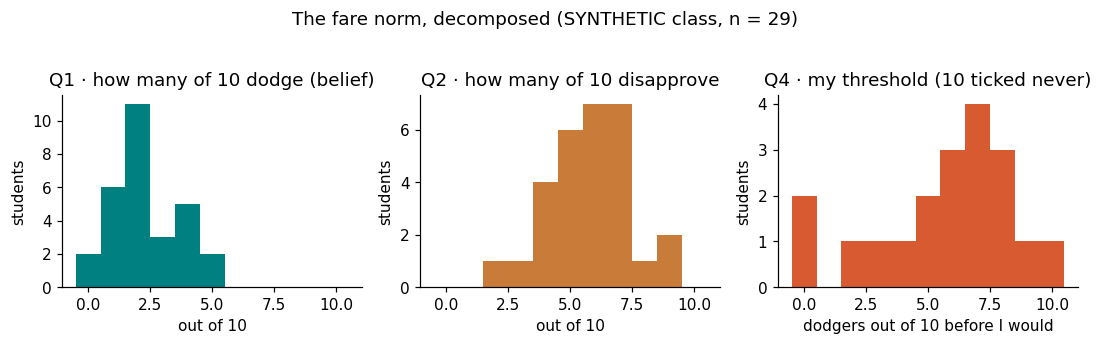

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3))
ax[0].hist(cls.emp_exp.dropna(), bins=np.arange(-0.5, 11), color=TEAL); ax[0].set_title("Q1 · how many of 10 dodge (belief)"); ax[0].set_xlabel("out of 10")
ax[1].hist(cls.norm_exp.dropna(), bins=np.arange(-0.5, 11), color=AMBER); ax[1].set_title("Q2 · how many of 10 disapprove"); ax[1].set_xlabel("out of 10")
never = cls.thr_fare_never.sum()
ax[2].hist(cls.thr_fare[~cls.thr_fare_never].dropna(), bins=np.arange(-0.5, 11), color=CORAL)
ax[2].set_title(f"Q4 · my threshold ({never} ticked never)"); ax[2].set_xlabel("dodgers out of 10 before I would")
for a in ax: a.set_ylabel("students")
fig.suptitle(f"The fare norm, decomposed ({CLASS_LABEL})", y=1.03); plt.tight_layout()

print(f"Median belief about others (Q1): {cls.emp_exp.median():.0f} of 10 dodge")
print(f"Median own threshold (Q4, excluding 'never'): {cls.thr_fare[~cls.thr_fare_never].median():.0f} of 10")
print(f"Ticked 'never': {never} of {len(cls)}")

### Is the norm holding, or under strain? Belief against threshold, person by person

*A side-glance, not a step on the ladder.* The next plot is something we can already see at Stop 1, before any translation, because two questions were asked in the same units. Keep it in mind: it is a static snapshot of each person's own rule. At Stop 5 the same thresholds go into a model where people react to each other, and what no snapshot can show, a cascade and a tipping point, appears.

Bicchieri's claim is that a norm-follower acts on what they *believe others do*. So each student has two numbers that can be compared: the belief about others (Q1, "I think 3 of 10 dodge") and their own threshold (Q4, "I would dodge once 6 of 10 do"). If a student's belief is already at or above their threshold, then by their own rule they should already be dodging: the norm is no longer what holds them back. **A norm is under strain when many people are in that position.** It then survives only because beliefs happen to sit below thresholds, and anything that pushed beliefs up (a news story, a visible week of fare evasion) would release those people at once.

The plot below is the honest way to see it: one dot per student, belief on the horizontal axis, threshold on the vertical, and the diagonal where the two are equal. Dots **on or below the diagonal** are students whose belief already meets their own condition. Students who ticked "never" have no threshold to meet and are drawn at the top as triangles.

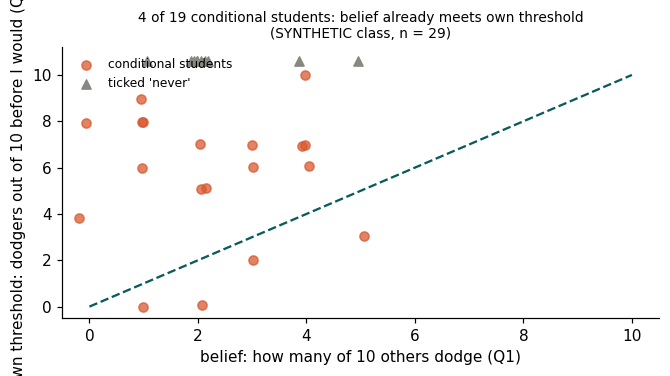

In [5]:
def strain_plot(belief=None):
    # Scatter of belief (Q1) against own threshold (Q4). If `belief` is given, everyone's belief is replaced by it.
    d = cls[["emp_exp", "thr_fare", "thr_fare_never"]].dropna(subset=["emp_exp"])
    cond = d[~d.thr_fare_never].dropna(subset=["thr_fare"]); nev = d[d.thr_fare_never]
    b = np.full(len(cond), belief) if belief is not None else cond.emp_exp.values
    released = (b >= cond.thr_fare.values).sum()
    jit = rng.normal(0, 0.1, len(cond))
    plt.scatter(b + jit, cond.thr_fare + jit, color=CORAL, alpha=0.75, label="conditional students")
    if len(nev): plt.scatter((np.full(len(nev), belief) if belief is not None else nev.emp_exp) + rng.normal(0, 0.1, len(nev)), np.full(len(nev), 10.6), marker="^", color=GRAY, label="ticked 'never'")
    plt.plot([0, 10], [0, 10], "--", color=DARK); plt.xlim(-0.5, 10.5); plt.ylim(-0.5, 11.2)
    plt.xlabel("belief: how many of 10 others dodge (Q1)"); plt.ylabel("own threshold: dodgers out of 10 before I would (Q4)")
    plt.legend(frameon=False, loc="upper left", fontsize=8)
    return released, len(cond)

released, n_cond = strain_plot()
plt.title(f"{released} of {n_cond} conditional students: belief already meets own threshold\n({CLASS_LABEL})", fontsize=9);

**How to read it.** The diagonal is the line "what I believe others do equals what it would take for me to do it". Above the line, the norm holds for that person; on or below it, the person's own rule says they should already be dodging. The number in the title counts the second group. If it is small, the norm is comfortably held; if it is a third of the class, the norm is one bad week away from unravelling.

### ▶ Try it
The slider replaces *everyone's* belief by a single value, as a convincing news story would ("4 in 10 passengers travel without a ticket"), and counts how many thresholds that one belief meets. It is a scenario about a belief shock, not a description of the class.

| Parameter | What it means | What to watch |
|---|---|---|
| Believe X/10 dodge | Everyone now believes X of 10 others dodge | The vertical line of dots moves right; every dot at or below the diagonal is a student whose condition is now met. Find the smallest X at which half the conditional class is released: that is how big a belief shock the norm could survive |

In [6]:
@interact(believed_share=IntSlider(value=int(cls.emp_exp.median()), min=0, max=10, description="Believe X/10 dodge"))
def strain(believed_share):
    released, n_cond = strain_plot(belief=believed_share)
    plt.title(f"If everyone believed {believed_share}/10 dodge,\n{released} of {n_cond} conditional students would already be dodging", fontsize=9)

interactive(children=(IntSlider(value=2, description='Believe X/10 dodge', max=10), Output()), _dom_classes=('…

**Where is the translation recipe here?**

| | |
|---|---|
| 1 · The material | Twelve questionnaire answers of five kinds: beliefs, ordinal scales, direct thresholds, a count, text, a category. |
| 2 · The rule | None yet. This stop only sorts the material and names what each piece is in the theory. |
| 3 · The distribution | The class's beliefs and thresholds as they are, before any translation. |
| Uncertainty carried forward | The 'never' tick-box is a censored answer: we know the threshold is beyond 10, not where. Whatever we do with those people later is a choice. |
| 4 · The use | Stop 2 (the scales), Stop 3 (the text), Stop 5 (the thresholds go straight into the models). |

*What this stop adds to the argument:* a simulation needs four kinds of number; research gives five kinds of material; the chain concept → indicator → variable → parameter is where the translation happens, and a theory of the phenomenon (here Bicchieri's) tells you which indicators to collect.

# Stop 2 · From scales: pseudo-quantification

## 2.1 Real data: “is it justifiable?” in Estonia, 1996 and 2011

The World Values Survey asks, in dozens of countries, whether a list of actions “can always be justified, never be justified, or something in between”, on a scale from 1 to 10. Estonia was surveyed in 1996 (about 1,000 people) and 2011 (about 1,500). Three of the items are in our data file: avoiding a fare, cheating on taxes, accepting a bribe. The counts in `wvs_estonia_justifiable.csv` are the published frequency tables of valid cases (unweighted), read from the survey documentation in the IHSN catalogue ([1996](https://catalog.ihsn.org/catalog/9087), [2011](https://catalog.ihsn.org/catalog/9049)); the same figures are in the [WVS online analysis tool](https://www.worldvaluessurvey.org/WVSOnline.jsp). Cite the data as Inglehart et al. (2014), in the references at the end; the per-item catalogue links are in the CSV's `source_url` column and in `wvs_estonia_README.txt`.

avoiding_fare    1996: 'never' 48.8%   mean 3.03
avoiding_fare    2011: 'never' 43.8%   mean 2.85
cheating_taxes   1996: 'never' 42.4%   mean 3.37
cheating_taxes   2011: 'never' 57.1%   mean 2.26
accepting_bribe  1996: 'never' 81.6%   mean 1.51
accepting_bribe  2011: 'never' 75.9%   mean 1.51


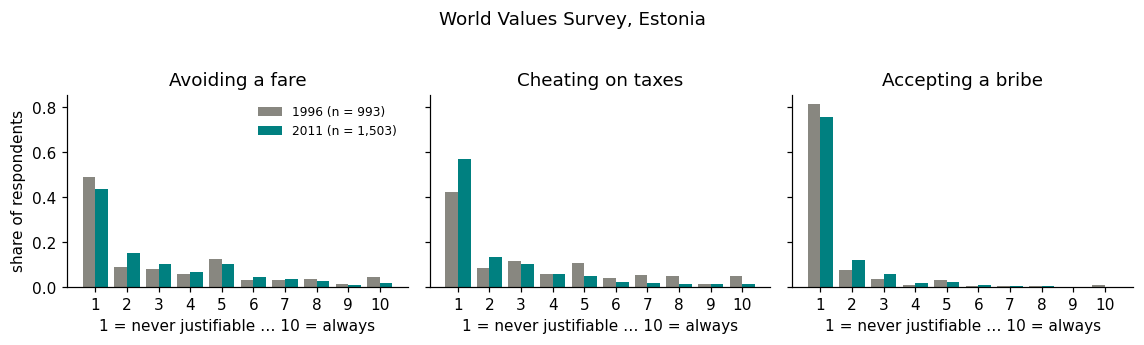

In [7]:
def shares(item, year):
    row = wvs[(wvs.item == item) & (wvs.year == year)].iloc[0]
    counts = row[SCALE_COLS].values.astype(float)
    return counts / counts.sum(), int(row.n_valid)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3), sharey=True)
for ax, item, title in zip(axes, ["avoiding_fare", "cheating_taxes", "accepting_bribe"], ["Avoiding a fare", "Cheating on taxes", "Accepting a bribe"]):
    for year, colour, dx in [(1996, GRAY, -0.2), (2011, TEAL, 0.2)]:
        p, n = shares(item, year)
        ax.bar(np.arange(1, 11) + dx, p, width=0.4, color=colour, label=f"{year} (n = {n:,})")
    ax.set_title(title); ax.set_xlabel("1 = never justifiable … 10 = always"); ax.set_xticks(range(1, 11))
axes[0].set_ylabel("share of respondents"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("World Values Survey, Estonia", y=1.03); plt.tight_layout()

for item in ["avoiding_fare", "cheating_taxes", "accepting_bribe"]:
    for year in (1996, 2011):
        p, n = shares(item, year); mean = (p * np.arange(1, 11)).sum()
        print(f"{item:16s} {year}: 'never' {p[0]:.1%}   mean {mean:.2f}")

Stop 2 has one objective: to translate an ordinal answer into a threshold, and to see that the translation is a choice. Before translating, look at what the scale actually contains. Three things to notice. First, the shapes differ: the bribe item is almost all “never”; the fare item has a long tail and a bump at 5. Second, the bump at 5 is the *midpoint of the scale* attracting undecided people, not a real cluster of opinion; any mapping has to decide what to do with it. Third, between 1996 and 2011 Estonians became stricter about taxes and looser about fares, while the bribe item barely moved. “Justifiable, 1 to 10” is three different kinds of number here, depending on what it is about.

### From a survey to a population you can draw from

Before any rule is applied, one generic tool that every later cell uses. A survey gives a list of answers: 1,503 Estonians, or 29 students. A model needs as many thresholds as it has agents, which may be 5,000 passengers or 1,600 households. The bridge is the *empirical distribution*: the share of respondents who gave each answer becomes the probability of that answer, and each agent draws one answer at random from it (with replacement, so the same answer can be drawn many times). From 29 students who answered 0 to 5 "out of eight", a city of 1,600 households is made by giving each household one of those 29 answers at random; a household's threshold is therefore always something a real student said, in the proportions the class said it. This is what `synthetic_respondents`, defined in the next code cell, does with the WVS counts, and what Stop 5 does with the class. It adds no information: it only lets a small list stand in for a large population *as if the list were the population*.


## 2.2 The problem: an ordinal number is not a quantity

The 1–10 answer looks like a number, so it is tempting to use it as one: average it, subtract it, feed it to a model. But the scale is **ordinal**: 8 is more permissive than 4, but nobody has established that it is twice as permissive, or that the step from 1 to 2 equals the step from 9 to 10. The number is a *rank with a label*.

To use it in the fare model we need each person's **threshold**: the share of other passengers dodging at which this person would dodge too, between 0 (dodges regardless) and 1 (only if everyone does), with “would never” beyond 1. Getting from “justifiable 7 out of 10” to a threshold is a **mapping**, and there are several defensible ones. We show three.

* **Linear.** *Logic:* attitude and behaviour are proportional; the higher the justification score, the lower the barrier to dodging, in equal steps. *Formula:* `t = (10 − s) / 9`, so 1 → 1.0, 5 → 0.56, 10 → 0. *The ends:* "never" becomes "only if everyone else does", reachable in principle. *The choice:* equal spacing, which the scale never promised.
* **Anchored.** *Logic:* survey answers have psychological anchors; people choose the extremes only when they mean them, and the midpoint when they are torn. So fix a few scale points to real behavioural boundaries and draw straight lines between them. *Anchors:* 10 → 0 (the opportunist: dodges regardless); 5 → 0.5 (the tipping point: dodges once the majority does); 2 → 1.0 (the conformist: only if everyone does); 1 → beyond 1 (the moralist: "would never"). *The ends:* "never" is literal, so 44% of Estonians are unreachable by any cascade. *The choice:* where to put the anchors.
* **Ordinal with jitter.** *Logic:* a score of 7 is a bucket, not a point. A hundred people who answered 7 do not share one threshold; they span a band between what 6 and 8 mean. Drawing each person's threshold at random inside the band restores that spread and prevents artificial clumps of identical agents in the model. *Formula:* `t ~ Uniform((10 − s)/9 ± 1/18)`, clipped to [0, 1]. *The ends:* the "never" band sits at the top and half of it lies beyond 1. *The choice:* the width of the band.

A fourth, **empirical calibration**, uses a second question asked in the model's units to learn the mapping from the data; section 2.3 builds it from the class. None is right. Each is a model of what the respondent meant, and Stop 4 treats the choice among them as one more source of uncertainty. The lecture notes compare the four in a table.

In [8]:
def to_threshold(s, mapping, r=None):
    '''Translate a 1–10 justifiability answer s (array) into a threshold in [0, 1]; values > 1 mean "never".'''
    s = np.asarray(s, dtype=float)
    if mapping == "linear":
        return (10 - s) / 9
    if mapping == "anchored":
        t = np.interp(s, [2, 5, 10], [1.0, 0.5, 0.0])   # anchors: 10 -> 0 (opportunist), 5 -> 0.5 (tipping point), 2 -> 1.0 (conformist); straight lines between
        return np.where(s == 1, 1.5, t)                 # 1 -> beyond 1: "would never", unreachable
    if mapping == "jitter":
        r = r or rng
        centre = (10 - s) / 9
        return np.clip(centre + r.uniform(-1/18, 1/18, size=s.shape), 0, 1.0001)
    raise ValueError(mapping)

def synthetic_respondents(item, year, n, r=None):
    '''Draw n imaginary respondents whose 1–10 answers follow the published WVS distribution.'''
    r = r or rng
    p, _ = shares(item, year)
    return r.choice(np.arange(1, 11), size=n, p=p)

**The three rules drawn.** Each panel shows what every scale answer becomes. Under linear and anchored a scale point goes to one threshold; under jitter it goes to a band, and the dots are a few example draws for each point. The grey zone is “beyond reach”.

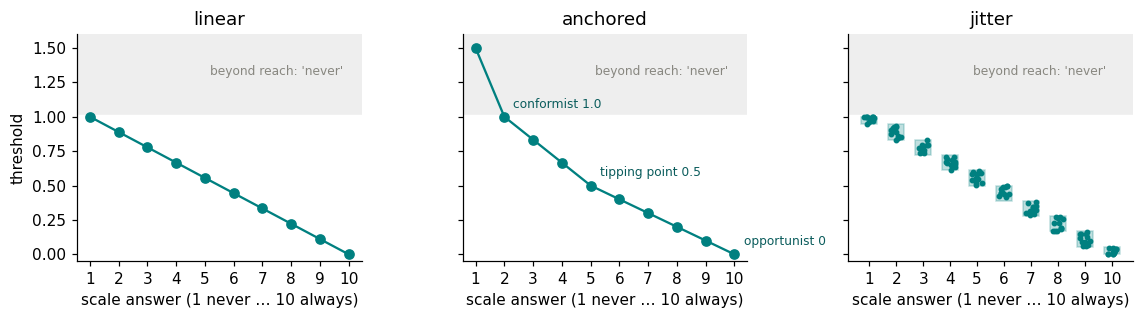

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3), sharey=True); rr = np.random.default_rng(7)
for ax, mapping in zip(axes, ["linear", "anchored", "jitter"]):
    ax.axhspan(1.02, 1.6, color="#eeeeee"); ax.text(9.8, 1.3, "beyond reach: 'never'", ha="right", fontsize=8, color=GRAY)
    if mapping == "jitter":
        for s in range(1, 11):
            lo, hi = max(0, (10 - s) / 9 - 1 / 18), min(1, (10 - s) / 9 + 1 / 18)
            ax.add_patch(plt.Rectangle((s - 0.3, lo), 0.6, hi - lo, color=TEAL, alpha=0.25))
            ax.scatter(s + rr.uniform(-0.2, 0.2, 12), to_threshold(np.full(12, s), "jitter", rr), s=8, color=TEAL)
    else:
        t = to_threshold(np.arange(1, 11), mapping)
        ax.plot(np.arange(1, 11), np.minimum(t, 1.5), "o-", color=TEAL)
        if mapping == "anchored":
            for s, txt in [(2, "conformist 1.0"), (5, "tipping point 0.5"), (10, "opportunist 0")]: ax.annotate(txt, (s, t[s - 1]), xytext=(6, 6), textcoords="offset points", fontsize=8, color=DARK)
    ax.set_title(mapping); ax.set_xticks(range(1, 11)); ax.set_xlabel("scale answer (1 never … 10 always)"); ax.set_ylim(-0.05, 1.6)
axes[0].set_ylabel("threshold"); plt.tight_layout()

**And applied to the data.** The next cell draws 10,000 imaginary respondents from the 2011 shares and translates the same 10,000 answers by each rule.

linear   : sparks (threshold exactly 0) 2.2%   never (beyond 1) 0%   middle (0.3–0.7) 25%
anchored : sparks (threshold exactly 0) 2.2%   never (beyond 1) 43%   middle (0.3–0.7) 25%
jitter   : sparks (threshold exactly 0) 1.1%   never (beyond 1) 22%   middle (0.3–0.7) 23%


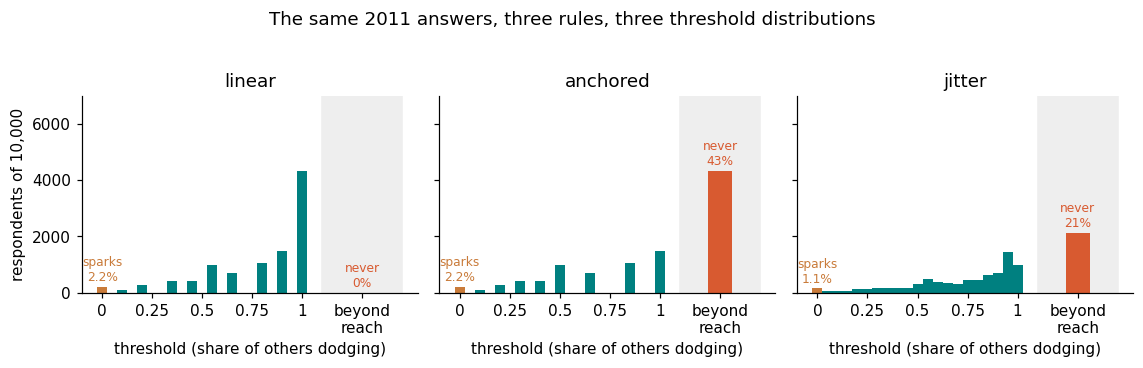

In [10]:
answers_2011 = synthetic_respondents("avoiding_fare", 2011, 10_000)

def threshold_hist(ax, t, title):
    # Histogram of thresholds: sparks (exactly 0) in amber, reachable thresholds in teal, "never" (beyond 1) as one coral bar in the grey zone.
    counts, edges = np.histogram(t[t <= 1], bins=np.linspace(-0.025, 1.025, 22))
    ax.bar((edges[:-1] + edges[1:]) / 2, counts, width=0.05, color=[AMBER] + [TEAL] * 20)
    ax.axvspan(1.1, 1.5, color="#eeeeee", zorder=0); ax.bar(1.3, (t > 1).sum(), width=0.12, color=CORAL)
    ax.text(0, counts[0] + 0.02 * len(t), f"sparks\n{(t <= 0.0001).mean():.1%}", ha="center", fontsize=8, color=AMBER)
    ax.text(1.3, (t > 1).sum() + 0.02 * len(t), f"never\n{(t > 1).mean():.0%}", ha="center", fontsize=8, color=CORAL)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1, 1.3]); ax.set_xticklabels(["0", "0.25", "0.5", "0.75", "1", "beyond\nreach"])
    ax.set_title(title); ax.set_xlabel("threshold (share of others dodging)"); ax.set_ylim(0, 0.7 * len(t))

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2), sharey=True)
for ax, mapping in zip(axes, ["linear", "anchored", "jitter"]):
    threshold_hist(ax, to_threshold(answers_2011, mapping), mapping)
axes[0].set_ylabel("respondents of 10,000")
fig.suptitle("The same 2011 answers, three rules, three threshold distributions", y=1.03); plt.tight_layout()
for mapping in ["linear", "anchored", "jitter"]:
    t = to_threshold(answers_2011, mapping)
    print(f"{mapping:9s}: sparks (threshold exactly 0) {(t <= 0.0001).mean():.1%}   never (beyond 1) {(t > 1).mean():.0%}   middle (0.3–0.7) {((t >= 0.3) & (t <= 0.7)).mean():.0%}")

**How to read the three panels.** The data never change between them: the same 10,000 imaginary Estonians, drawn from the 2011 answers. Only the rule changes. The horizontal axis is the threshold the model will use, from 0 to 1, plus a grey zone on the right for thresholds *beyond 1*, which no share of others can ever reach. The bars count people. Three groups are coloured: the amber bar at 0 is the **sparks**, people who dodge regardless (they answered 10); the coral bar in the grey zone is the **nevers**, placed beyond reach; the teal bars are everyone in between. Under the linear rule nobody is beyond reach: the 44% who answered "never" stand at exactly 1.0, reachable in principle if everyone else dodged. Under the anchored rule the same 44% move into the grey zone. Under jitter the "never" band straddles 1, so half of them (22%) end up beyond reach and half just below it. The sparks go 2% → 2% → 1% (jitter spreads the 10s over a small band, so only half land exactly at 0). The middle of the distribution hardly differs. That is the general pattern: mappings disagree most about the extreme answers, and the extremes are exactly what decides a cascade, because the sparks start it and the "nevers" cap it. So "the mapping matters" is true with a qualifier: it matters most for the two groups at the ends, and those are the groups that decide whether anything happens at all.

### ▶ Try it
Pick the item, the year and the mapping, and see what the model would receive. Left panel: what people said. Right panel: what the model gets, with the two decisive groups coloured.

| Parameter | What it means | What to watch |
|---|---|---|
| Item | Which WVS question: fare, taxes, bribe | The bribe item is almost all "never": under the anchored mapping three quarters of the population are unreachable |
| Year | 1996 or 2011 answers | The fare item loosened, the tax item tightened: the sparks and the nevers move in opposite directions |
| Mapping | linear / anchored / jitter | The amber (sparks) and coral (never) bars change with the rule while the left panel stays the same; the teal middle barely moves |

In [11]:
@interact(item=Dropdown(options=["avoiding_fare", "cheating_taxes", "accepting_bribe"], value="avoiding_fare", description="Item"),
          year=Dropdown(options=[1996, 2011], value=2011, description="Year"),
          mapping=Dropdown(options=["linear", "anchored", "jitter"], value="linear", description="Mapping"))
def show_mapping(item, year, mapping):
    s = synthetic_respondents(item, year, 10_000); t = to_threshold(s, mapping)
    fig, ax = plt.subplots(1, 2, figsize=(9, 3))
    p, n = shares(item, year); ax[0].bar(range(1, 11), p, color=GRAY); ax[0].set_title(f"{item} {year}: what people said"); ax[0].set_xlabel("1 never … 10 always")
    threshold_hist(ax[1], t, f"what the model gets under the {mapping} rule")
    plt.tight_layout()

interactive(children=(Dropdown(description='Item', options=('avoiding_fare', 'cheating_taxes', 'accepting_brib…

## 2.3 Avoiding the mapping, way one: ask in the model's units

Q4 did not ask how justifiable dodging is; it asked *at how many dodgers out of ten would you dodge*. Divide by 10 and that is the threshold itself: no rule, no choice. Q5 did the same for the neighbourhood (how many of eight like you; divide by 8). The classic example is the Detroit Area Study (Farley et al., 1978): instead of asking how tolerant people were, interviewers showed cards picturing streets with different mixes of households and asked which the respondent would move into, and Clark (1991) used exactly those distributions to test Schelling's model. When you design your own study, this is the first thing to try.

Ticked 'never' on Q4: 10 of 29 students: a threshold beyond 1, as in the anchored rule


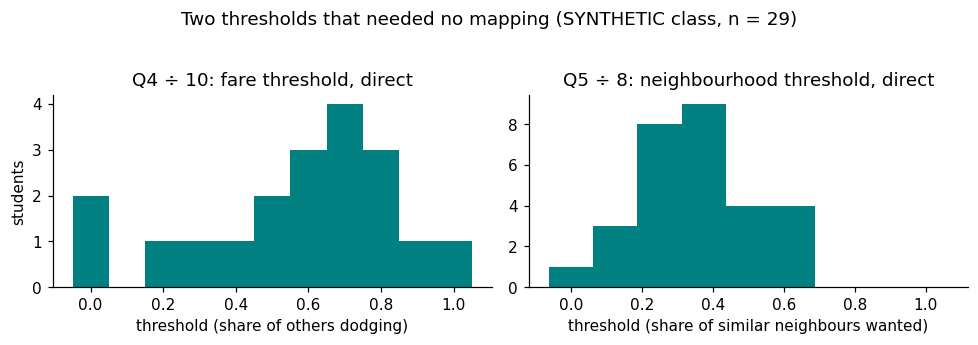

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(cls.thr_fare[~cls.thr_fare_never].dropna() / 10, bins=np.linspace(-0.05, 1.05, 12), color=TEAL); ax[0].set_title("Q4 ÷ 10: fare threshold, direct"); ax[0].set_xlabel("threshold (share of others dodging)"); ax[0].set_ylabel("students")
ax[1].hist(cls.thr_nbr.dropna() / 8, bins=np.linspace(-1/16, 1 + 1/16, 10), color=TEAL); ax[1].set_title("Q5 ÷ 8: neighbourhood threshold, direct"); ax[1].set_xlabel("threshold (share of similar neighbours wanted)")
plt.suptitle(f"Two thresholds that needed no mapping ({CLASS_LABEL})", y=1.03); plt.tight_layout()
print(f"Ticked 'never' on Q4: {cls.thr_fare_never.sum()} of {len(cls)} students: a threshold beyond 1, as in the anchored rule")

Both histograms are already in the model's units: Stop 5 draws from the right one for Schelling's households and could draw from the left one for the cascade. The one thing left to decide is what to do with the students who ticked "never": the honest answer is the same as the anchored rule's, a threshold beyond reach.

## 2.4 Avoiding the mapping, way two: ask twice, and let the pair teach you the rule

When the same attitude has been measured both on a scale and in the model's units, the pair *is* a mapping, learned from people instead of assumed. The recipe, for the fare pair (Q3 on the 1–10 scale, Q4 the direct threshold):

1. Group the students by their Q3 answer.
2. In each group, average the direct thresholds (Q4 ÷ 10). That average is what "a 7" means in threshold units, for this population.
3. Note the share in each group who ticked "never"; that share goes beyond reach.
4. Fill scale points nobody chose by drawing a straight line between their neighbours, and say so.

The result is the fourth rule, **calibrated**: look up each respondent's scale point in the table and give them that group's average threshold (or, with the group's "never" share as probability, a threshold beyond reach). The correlation between the scale answer and the direct answer says how much to trust the table: high means the scale orders people as the direct question does; below about 0.3 the two questions are not measuring the same thing, and the scale should not be mapped at all. The cell below builds the table and the plot, and adds `"calibrated"` to `to_threshold`, so the WVS data can be translated by a rule the class provided.

,mean threshold (direct),share 'never',students
justif,,,
1,0.82,1.0,10
2,0.82,0.0,6
3,0.70,0.0,4
4,0.61,0.0,0
5,0.52,0.0,4
6,0.35,0.0,2
7,0.30,0.0,1
8,0.20,0.0,0
9,0.10,0.0,0


Correlation between the 1–10 answer (Q3) and the direct threshold (Q4): 0.94  (n = 19; sign flipped so that higher = more agreement)
WVS 2011 translated with the class's calibration: sparks 2.2%, never 43%


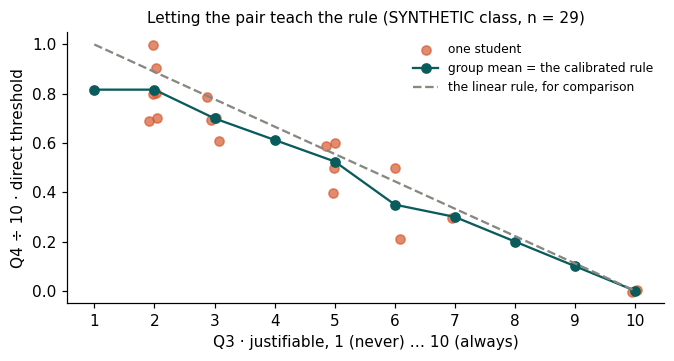

In [13]:
pair = cls[["justif", "thr_fare", "thr_fare_never"]].dropna(subset=["justif"])
level_mean = pair[~pair.thr_fare_never].groupby("justif").thr_fare.mean() / 10      # step 2: mean direct threshold at each scale point
never_share = pair.groupby("justif").thr_fare_never.mean()                           # step 3: share who ticked 'never' at each point
calib = pd.DataFrame({"mean threshold (direct)": level_mean, "share 'never'": never_share, "students": pair.groupby("justif").size()}).reindex(range(1, 11))
calib["mean threshold (direct)"] = calib["mean threshold (direct)"].interpolate(limit_direction="both")   # step 4: fill scale points nobody chose
calib["share 'never'"] = calib["share 'never'"].fillna(0); calib["students"] = calib["students"].fillna(0).astype(int)
display(calib.round(2))

_old_to_threshold = to_threshold
def to_threshold(s, mapping, r=None):
    # As before, plus "calibrated": the class's own mean threshold at each scale point, with the class's share of "never" placed beyond 1.
    if mapping != "calibrated":
        return _old_to_threshold(s, mapping, r)
    r = r or rng; s = np.asarray(s, dtype=int)
    t = calib["mean threshold (direct)"].values[s - 1]
    is_never = r.random(s.shape) < calib["share 'never'"].values[s - 1]
    return np.where(is_never, 1.5, t)

valid = pair[~pair.thr_fare_never].dropna(subset=["thr_fare"])
jit = rng.normal(0, 0.08, len(valid))
plt.scatter(valid.justif + jit, valid.thr_fare / 10 + jit / 10, color=CORAL, alpha=0.7, label="one student")
plt.plot(calib.index, calib["mean threshold (direct)"], "o-", color=DARK, label="group mean = the calibrated rule")
plt.plot(range(1, 11), [to_threshold(np.array([s]), "linear")[0] for s in range(1, 11)], "--", color=GRAY, label="the linear rule, for comparison")
plt.xlabel("Q3 · justifiable, 1 (never) … 10 (always)"); plt.ylabel("Q4 ÷ 10 · direct threshold"); plt.xticks(range(1, 11)); plt.ylim(-0.05, 1.05)
plt.title(f"Letting the pair teach the rule ({CLASS_LABEL})", fontsize=10); plt.legend(frameon=False, fontsize=8)
print(f"Correlation between the 1–10 answer (Q3) and the direct threshold (Q4): {-valid[['justif', 'thr_fare']].corr().iloc[0, 1]:.2f}  (n = {len(valid)}; sign flipped so that higher = more agreement)")
t_cal = to_threshold(answers_2011, "calibrated")
print(f"WVS 2011 translated with the class's calibration: sparks {(t_cal <= 0.0001).mean():.1%}, never {(t_cal > 1).mean():.0%}")

**How to read it.** Each coral dot is one student: their scale answer across, their direct threshold up. The dark line joins the group means and *is* the calibrated rule; the grey dashed line is the linear rule for comparison. Where the dark line runs below the grey one, the class's threshold at that scale point is lower than equal spacing would assume. The table above the plot is the same rule as numbers; rows with 0 students were filled by interpolation. With 29 students most rows rest on one or two people, so the rule is noisy; with a few hundred it would be the best rule available.

The same recipe works for any pair. The class also has the neighbourhood pair, Q6 (a 1–5 Likert item) against Q5 ÷ 8: group by the Likert answer, average the direct thresholds, and anyone who only has the Likert item can borrow the result. The notebook prints that table too:

In [14]:
valid_nbr = cls[["likert_nbr", "thr_nbr"]].dropna()
print(f"Correlation between the Likert answer (Q6) and the direct threshold (Q5): {valid_nbr.corr().iloc[0, 1]:.2f}  (n = {len(valid_nbr)})")
print("Mean direct threshold (Q5 ÷ 8) at each Likert level: this table is the calibrated rule for Q6")
print((valid_nbr.groupby("likert_nbr").thr_nbr.mean() / 8).round(2).to_string())

Correlation between the Likert answer (Q6) and the direct threshold (Q5): 0.66  (n = 29)
Mean direct threshold (Q5 ÷ 8) at each Likert level: this table is the calibrated rule for Q6
likert_nbr
1.0    0.16
2.0    0.31
3.0    0.44
5.0    0.62


Whatever rule you use, the output is the same object: one threshold per agent, a distribution across the population. The next question, Stop 4's, is how sure we are of it.

**Where is the translation recipe here?**

| | |
|---|---|
| 1 · The material | The WVS 1–10 'justifiable' item (ordinal), and the class's Q3 (same scale), Q4 and Q5 (direct thresholds) and Q6 (Likert). |
| 2 · The rule | Four alternatives from scale to threshold: linear, anchored, ordinal-with-jitter, and empirical calibration from a paired question. For Q4 and Q5 themselves, no rule: the question already asked in the model's units. |
| 3 · The distribution | A threshold distribution per rule; the share at 0 and the share beyond 1 differ most. |
| Uncertainty carried forward | The choice of rule itself. Four defensible rules give four distributions; which is 'right' cannot be settled from the scale alone. Also the interpolation in the calibration table. |
| 4 · The use | Agent attributes: each person's threshold, into the cascade and the city at Stop 5. Stop 4 measures how much the rule matters. |

*What this stop adds to the argument:* an ordinal scale is a rank with a label, not a quantity; turning it into a model input is a choice among defensible rules; the rules disagree most about the extreme answers, which are the ones that decide a cascade; and the best way out is to ask the question in the model's units, or to ask it twice and let the pair teach you the rule.

# Stop 3 · From words and from experts

Not everything comes on a scale. Interviews produce sentences, and some quantities nobody has ever surveyed. Each has a standard route to a number, and each route is a translation with a choice in it.

## 3.1 Text → categories → shares

Q11 asked, in one sentence, why you trust the bus timetable as much as you do. Qualitative researchers turn such sentences into categories by **coding**: reading each answer and assigning it to one or more themes. Once coded, the answers are counts; counts divided by the total are shares; and shares are probabilities a simulation can use (“a randomly drawn passenger has a 40% chance of being an *experience-based truster*”).

The cell below does the crudest possible coding, by keyword dictionary, so that every step is visible. Real coding is done by people (two coders, and you report how often they agree), or, increasingly, by a language model with the coding scheme in the prompt, which is the subject of the machine-learning seminar later in the course.

,count,share of answers
unreliability,13,0.45
own experience,7,0.24
does not use,6,0.21
information source,3,0.10



Three answers and how they were coded:
  'Never checked it'  ->  ['does not use']
  'Buses are often late in winter'  ->  ['unreliability']
  'Sometimes the bus leaves early'  ->  ['unreliability']


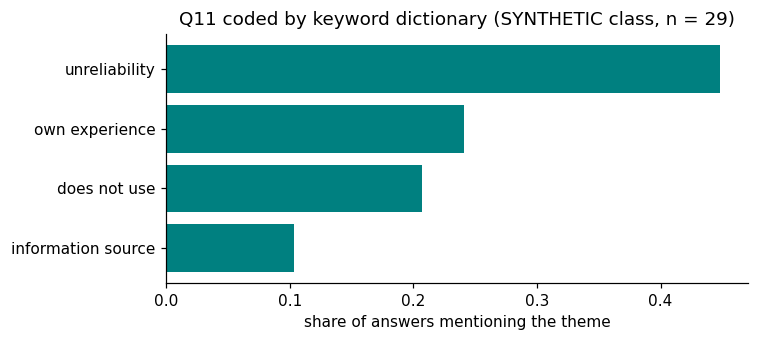

In [15]:
CODEBOOK = {   # theme -> keywords (crude on purpose: every step visible)
    "own experience":      ["experience", "usually", "always", "never late", "on time", "reliable"],
    "unreliability":       ["late", "early", "delay", "winter", "traffic", "miss"],
    "information source":  ["app", "real-time", "display", "sign", "website"],
    "does not use":        ["don't use", "do not use", "rarely", "never use", "never checked"],
}
def code_sentence(text):
    text = str(text).lower(); hits = [theme for theme, kws in CODEBOOK.items() if any(k in text for k in kws)]
    return hits or ["other / uncoded"]

coded = cls.trust_why.dropna().apply(code_sentence)
counts = pd.Series([t for themes in coded for t in themes]).value_counts()
share = counts / len(coded)
display(pd.DataFrame({"count": counts, "share of answers": share.round(2)}))

plt.barh(share.index[::-1], share.values[::-1], color=TEAL); plt.xlabel("share of answers mentioning the theme")
plt.title(f"Q11 coded by keyword dictionary ({CLASS_LABEL})"); plt.tight_layout()
print("\nThree answers and how they were coded:")
for s, c in list(zip(cls.trust_why.dropna(), coded))[:3]: print(f"  '{s}'  ->  {c}")

Look at the “other / uncoded” share. That is the honest measure of how good the codebook is, and it is the first number to report. In a real study you would read the uncoded sentences, extend the codebook, and have a second person code a sample independently; the share of sentences on which the two coders agree (inter-coder reliability) is the uncertainty of this translation, and it belongs in Stop 4 with the others.

**A preview of coding with a language model.** The same job can be given to a large language model with a prompt such as:

> *You are coding open survey answers. Assign each answer to one or more of these themes: own experience, unreliability, information source, does not use, other. Answer: “{sentence}”. Return only the theme names.*

Run on all 29 sentences this takes seconds; the quality question is the same as for a human coder (does it agree with a second coder on a sample?), and the seminar on machine learning and language models takes it up properly.

## 3.2 A quantity nobody surveyed: expert elicitation

The fare model needs a number no survey gives: *how often is a ticket checked?* When no data exist, the standard honest route is **structured expert elicitation** (O'Hagan et al., 2006): ask people who know the system (a bus driver, an inspector, a frequent passenger) for three numbers each, a *lowest plausible*, a *most likely* and a *highest plausible* value, and turn the three into a distribution.

The **PERT distribution** is built for exactly this. It is a smooth bell that lives between the lowest and the highest value, has its peak at the most likely one, and leans towards whichever side the expert left more room on; its mean is (lowest + 4 × most likely + highest) / 6. Asking for three numbers rather than one does two things: it stops the expert from giving a false point estimate, and it records how confident they are, because a confident expert gives a narrow range and an unsure one a wide range.

Two experts giving different triples is normal. Combining them, usually by *mixing* the two distributions (pooling their draws), is part of the method, and the disagreement between them is the uncertainty to carry into the model: it is why the inspection rate enters Stop 5 as a distribution rather than a number.

**How to read the plot below.** The horizontal axis is the quantity being elicited, the share of trips on which a ticket is checked. The bars count how many of 20,000 imaginary draws fell at each value, so each coloured shape is one expert's belief turned into a distribution. Where the two shapes overlap, the experts agree; the printed 90% range of the mixture is what a report would carry.

### ▶ Try it

| Parameter | What it means | What to watch |
|---|---|---|
| Lowest / Most likely / Highest | Expert 1's three numbers | The peak follows "most likely"; the bell leans towards the side with more room. Narrow the range: a confident expert, a tall thin shape. Widen it: a long tail, and the 90% range of the mixture grows |
| Add a 2nd expert | A second triple, 0.05 / 0.15 / 0.40 | The overlap is where they agree. Move expert 1 so the shapes do not overlap at all: the mixture becomes two-humped, and the report should say so rather than average it away |

In [16]:
def pert(low, mode, high, n, r=None):
    '''Draw n values from a PERT distribution: a smooth bell between low and high, peaked at mode.'''
    r = r or rng
    a = 1 + 4 * (mode - low) / (high - low); b = 1 + 4 * (high - mode) / (high - low)
    return low + (high - low) * r.beta(a, b, n)

@interact(low=FloatSlider(value=0.02, min=0, max=0.5, step=0.01, description="Lowest %"),
          mode=FloatSlider(value=0.08, min=0, max=0.5, step=0.01, description="Most likely"),
          high=FloatSlider(value=0.25, min=0, max=0.6, step=0.01, description="Highest"),
          second_expert=Checkbox(value=True, description="Add a 2nd expert (0.05 / 0.15 / 0.40)"))
def elicit(low, mode, high, second_expert):
    if not (low < mode < high): print("Need lowest < most likely < highest"); return
    x = pert(low, mode, high, 20_000)
    plt.hist(x, bins=60, range=(0, 0.6), color=TEAL, alpha=0.8, label=f"expert 1: {low:.2f} / {mode:.2f} / {high:.2f}")
    if second_expert:
        y = pert(0.05, 0.15, 0.40, 20_000); plt.hist(y, bins=60, range=(0, 0.6), color=AMBER, alpha=0.6, label="expert 2: 0.05 / 0.15 / 0.40")
        mix = np.concatenate([x, y]); print(f"Mixture of both experts: median {np.median(mix):.2f}, 90% range {np.percentile(mix, 5):.2f}–{np.percentile(mix, 95):.2f}")
    plt.xlabel("share of trips on which tickets are checked"); plt.ylabel("draws"); plt.legend(frameon=False)
    plt.title("Expert elicitation: three numbers become a distribution")

interactive(children=(FloatSlider(value=0.02, description='Lowest %', max=0.5, step=0.01), FloatSlider(value=0…

**Where is the translation recipe here?**

| | |
|---|---|
| 1 · The material | Free-text answers (Q11); a quantity with no data (how often tickets are checked). |
| 2 · The rule | A codebook (themes and keywords, or a human or LLM coder); a lowest / most likely / highest triple from each expert, turned into a PERT distribution. |
| 3 · The distribution | Theme shares; a PERT distribution per expert and their mixture. |
| Uncertainty carried forward | For text: the uncoded share and the agreement between two coders. For judgement: the width of each expert's range and the disagreement between experts. |
| 4 · The use | Theme shares become probabilities of agent types (an attribute); the inspection rate becomes a parameter of the fare model at Stop 5. |

*What this stop adds to the argument:* when there is no scale, the translation is still a written rule: a codebook, an elicitation protocol. Each produces a distribution, not a number, and each has a quality measure (uncoded share, inter-coder agreement, disagreement between experts) that is the uncertainty to carry forward.

# Stop 4 · Quantifying the uncertainty

Every translation so far produced a distribution rather than a number, and for different reasons. Naming the reasons matters, because they are handled differently and because one of them is usually much larger than the others.

| Source | What it is | Where it came from today | How it enters the Monte Carlo loop |
|---|---|---|---|
| **Sampling** | you asked n people, not everyone | WVS n ≈ 1,500; class n ≈ 29 | resample the respondents (the bootstrap from the Monte Carlo seminar) |
| **Translation** | the mapping was a choice | linear / anchored / jitter / calibrated; the codebook; the elicitation protocol | run the model under each mapping, or draw the mapping at random each run |
| **Heterogeneity** | people differ; a population is a distribution, not a point | the spread of thresholds | give each agent its own draw (this is not “error”: it is the phenomenon) |
| **Structural** | the rule itself could be different | “dodge if share ≥ threshold” vs a rule with inspections in it; free fares in Tallinn since 2013 changing what the item means | compare rule variants; report that the result is conditional on the rule |

The four are worth separating because they are different in kind, not only in size:

* **Sampling and translation are epistemic**: they come from limited knowledge and from the researcher's choices. With unlimited money and a perfect mind they would shrink to zero.
* **Heterogeneity is aleatoric**: it is the diversity of the world itself. Even a researcher who knew everything would still face a wide distribution, because people differ. It is not to be reduced; it is to be carried into the model.
* **Structural uncertainty is about the system, not the data**: the system itself may change what the numbers mean. Free fares change what "dodging" is, from a rule violation to a non-issue, and no amount of data under the old meaning fixes that.

The first three can be put into one loop; the fourth cannot be averaged away and must be reported as a condition.

## 4.1 Two definitions, before any plot

Recall from section 2.1 how a list of answers becomes a population to draw from: each answer's share becomes its probability, and every agent draws one answer at random, with replacement. Both definitions below rest on it.

**Sampling uncertainty** is the doubt that comes from the "as if" of section 2.1. A different 29 students, or a different 1,503 Estonians, would have given a somewhat different list. To measure it we do what the Monte Carlo seminar called the bootstrap: draw an imaginary survey of the same size n from the empirical distribution, compute the statistic, and repeat a few hundred times. The spread of those statistics is the sampling uncertainty; it shrinks like 1/√n.

**Translation uncertainty** is the doubt that comes from the rule. Keep the survey fixed and change only the mapping from Stop 2: the statistic moves. The distance it moves is the translation uncertainty; it does not shrink with n at all, because every extra respondent is translated by the same disputed rule.

## 4.2 The two side by side

The statistic in the next plot is the simplest one that matters for Stop 5: **the share of people whose threshold is 0.4 or less**, that is, who would dodge once 4 in 10 of the others did. It is a stand-in for the full cascade, fast enough to compute thousands of times. Because thresholds come from a 1–10 scale, the statistic is really a question about scale points: at the level 0.4, the linear rule counts everyone who answered 7 to 10 (6 → 0.44, just above the line); the anchored rule counts 6 to 10 (6 → 0.40, exactly on it); the jitter rule counts 7 to 10 and about a tenth of the 6s (their band runs from 0.39 to 0.50). So the gap between the linear and the anchored band is exactly the share who answered 6, which in 2011 was 4.4%. That is what "the rules disagree" means in concrete terms: they disagree about which side of the line one scale point falls.

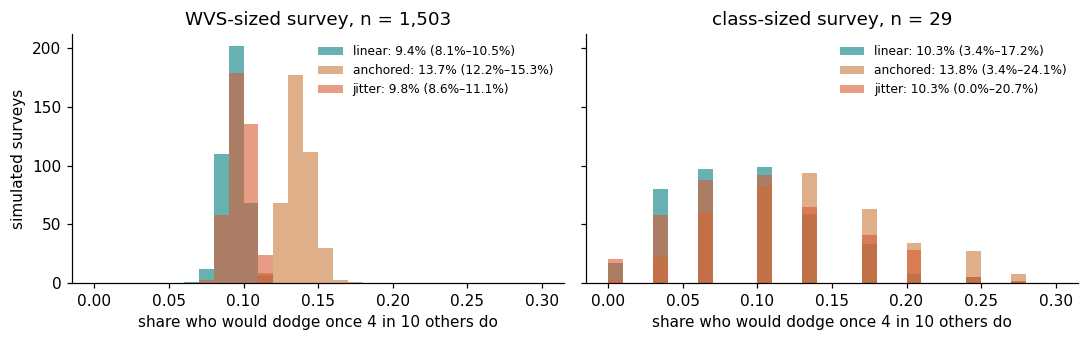

In [17]:
def share_reachable(answers, mapping, level=0.4, r=None):
    '''Share of respondents whose threshold is at or below `level` under a mapping.'''
    return (to_threshold(answers, mapping, r) <= level).mean()

def propagate(item, year, n, mappings, reps=400, r=None):
    '''Resample n respondents reps times (sampling uncertainty) under each mapping (translation uncertainty).'''
    r = r or rng
    out = {}
    for m in mappings:
        vals = [share_reachable(synthetic_respondents(item, year, n, r), m, r=r) for _ in range(reps)]
        out[m] = np.array(vals)
    return out

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, n, title in zip(axes, [1503, 29], ["WVS-sized survey, n = 1,503", "class-sized survey, n = 29"]):
    res = propagate("avoiding_fare", 2011, n, ["linear", "anchored", "jitter"])
    for (m, vals), colour in zip(res.items(), [TEAL, AMBER, CORAL]):
        ax.hist(vals, bins=30, range=(0, 0.3), alpha=0.6, color=colour, label=f"{m}: {np.median(vals):.1%} ({np.percentile(vals, 5):.1%}–{np.percentile(vals, 95):.1%})")
    ax.set_title(title); ax.set_xlabel("share who would dodge once 4 in 10 others do"); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("simulated surveys"); plt.tight_layout()

**How to read it.** Horizontal axis: the value of the statistic (the share reachable at 35%) that one imaginary survey produced. Vertical axis: how many of the 400 imaginary surveys produced that value. One colour per rule, all three applied to the *same* 400 surveys. So the **width** of a coloured histogram is the sampling uncertainty at that n, and the **distance between the centres** of the colours is the translation uncertainty; the legend gives each rule's median and 90% range.

Left, n = 1,503: each histogram is narrow (about ±1 point) but they sit in different places: translation uncertainty is larger than sampling uncertainty, and no number of extra respondents would move the centres closer together. Right, n = 29: the histograms are so wide (0% to 20%) that they lie on top of one another; here sampling dominates and arguing about the rule is pointless until more people are asked. **What it means for us:** before spending effort on reducing an uncertainty, find out which one dominates. A thousand more interviews would not have helped the left panel; a better question would. A better question would not have helped the right panel; more people would.

### ▶ Try it
**How to read the plot.** Each histogram is 300 imaginary surveys of size n; the horizontal axis is the statistic each survey produced (the share of people whose threshold is at or below the chosen level), and the width of a histogram is the sampling uncertainty at that n. The three colours are the three rules applied to the *same* surveys; the distance between their centres is the translation uncertainty.

| Parameter | What it means | What to watch |
|---|---|---|
| Survey size n | How many people each imaginary survey asks | The histograms narrow like 1/√n, but their centres do not move: more people never shrink the gap between rules |
| Year | 1996 or 2011 answers | The whole picture shifts; the gap between rules changes size, because the rules disagree about the ends and the ends moved |
| Others dodging (level) | The share of others at which we count a person as reachable | Move it slowly: at some levels the rules coincide (the cut falls between the same scale points for all three), at others one scale point switches sides and they split. The gap is a property of the level, not a constant |

Task: at what n does the sampling band become narrower than the gap between rules? That n is the point beyond which more interviews stop helping and a better question is the only way forward.

In [18]:
@interact(n=IntSlider(value=200, min=20, max=2000, step=20, description="Survey size n"),
          year=Dropdown(options=[1996, 2011], value=2011, description="Year"),
          level=FloatSlider(value=0.4, min=0.05, max=0.9, step=0.05, description="Others dodging"))
def bands(n, year, level):
    r = np.random.default_rng(1)
    for m, colour in zip(["linear", "anchored", "jitter"], [TEAL, AMBER, CORAL]):
        vals = np.array([share_reachable(synthetic_respondents("avoiding_fare", year, n, r), m, level, r) for _ in range(300)])
        plt.hist(vals, bins=np.linspace(0, max(0.3, min(1, vals.max() + 0.05)), 31), alpha=0.6, color=colour, label=f"{m}: {np.median(vals):.1%} ± {2*vals.std():.1%}")
    plt.xlabel(f"share who would dodge once {level:.0%} of others do"); plt.ylabel("simulated surveys"); plt.legend(frameon=False, fontsize=8)
    plt.title(f"n = {n}: sampling bands vs translation gap")

interactive(children=(IntSlider(value=200, description='Survey size n', max=2000, min=20, step=20), Dropdown(d…

## 4.3 Heterogeneity is not noise

The third source deserves its own paragraph, because it is the one students most often average away by reflex. A survey mean is a summary of a population; a model agent is one person. If every agent is given the mean, the model contains a population of identical clones and none of the mechanisms that depend on *who moves first* can operate. The threshold distribution is not uncertainty *about* the population; it *is* the population. Stop 5 shows what happens when it is replaced by its mean.

## 4.4 Structural uncertainty: the thing a number cannot carry

Tallinn made public transport free for registered residents in 2013; most Estonian counties followed for county buses in 2018; Tartu kept its fares. A person answering the WVS question in 2011 and the same question today may be talking about different things, and a Tallinn resident's “never justifiable” means something else once there is no fare to dodge. No mapping fixes this. The honest treatment is to say which rule and which world the number belongs to, and to report the result as conditional on it. That sentence belongs in the report, next to the result (Stop 6).

**Where is the translation recipe here?**

| | |
|---|---|
| 1 · The material | The outputs of Stops 2 and 3: threshold distributions under several rules, from surveys of different sizes. |
| 2 · The rule | None new: this stop asks how sure we are of the previous rules. |
| 3 · The distribution | A band per source: resampling for sampling uncertainty, one run per rule for translation uncertainty, the spread itself for heterogeneity. |
| Uncertainty carried forward | All four, now named: sampling (shrinks with n), translation (does not), heterogeneity (is the phenomenon), structural (must be stated). Stop 5 asks which of them moves the outcome. |
| 4 · The use | Stop 5 runs the models inside these bands; Stop 6 says how to report them. |

*What this stop adds to the argument:* uncertainty has four sources that behave differently; the Monte Carlo loop carries three of them, the fourth must be stated; and the first job is to find out which one dominates.

# Stop 5 · Into the model: emergence

## 5.1 Schelling's city with real thresholds: the one changed line

At the end of the Monte Carlo seminar the Schelling model had the same threshold for every household and we promised that only one line would change. Here it is. The city is as before: a 40 × 40 grid, two kinds of household (teal and orange) and 10% empty cells; each round every household with fewer similar neighbours than its threshold moves to a random empty cell; after 40 rounds we measure segregation as the average household's share of similar neighbours (0.5 is a perfectly mixed city, 1.0 a fully separated one).

The one changed line is the threshold. Before, one number for all 1,600 households. Now, the class's answers to Q5 (how many of eight neighbours should be like you, divided by 8), and each household draws one of the 29 answers at random, with replacement, as section 2.1 described. So the middle city below gives every household the *class mean*; the right city gives every household *one real student's answer*, in the proportions the class gave them.

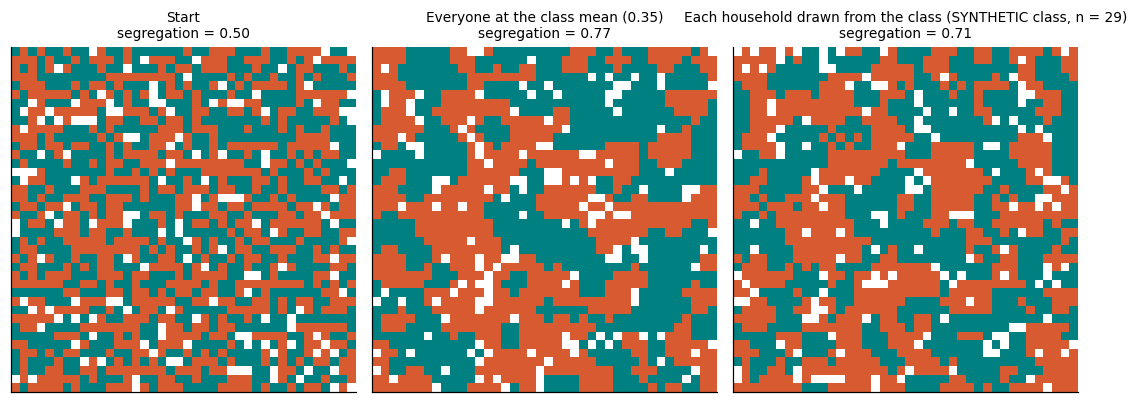

In [19]:
EMPTY, A, B = 0, 1, 2
def new_city(size=30, empty_share=0.1, seed=0):
    r = np.random.default_rng(seed)
    return r.choice([EMPTY, A, B], size=(size, size), p=[empty_share, (1 - empty_share) / 2, (1 - empty_share) / 2])
def share_similar(city):
    size = city.shape[0]; padded = np.pad(city, 1, mode="wrap")
    same = np.zeros(city.shape); occupied = np.zeros(city.shape)
    for dx in (-1, 0, 1):
        for dy in (-1, 0, 1):
            if dx == 0 and dy == 0: continue
            nb = padded[1 + dx: 1 + dx + size, 1 + dy: 1 + dy + size]
            same += (nb == city) & (nb != EMPTY); occupied += nb != EMPTY
    return np.where(occupied > 0, same / np.maximum(occupied, 1), 1.0)
def run_city(city, threshold, steps=40, seed=0):
    r = np.random.default_rng(seed); city = city.copy()
    for _ in range(steps):
        unhappy = (city != EMPTY) & (share_similar(city) < threshold)
        movers = np.argwhere(unhappy); empties = np.argwhere(city == EMPTY)
        if len(movers) == 0: break
        r.shuffle(movers); r.shuffle(empties)
        for (i, j), (k, l) in zip(movers, empties): city[k, l], city[i, j] = city[i, j], EMPTY
    return city
def segregation(city):
    s = share_similar(city); return s[city != EMPTY].mean()

from matplotlib.colors import ListedColormap
cmap = ListedColormap(["white", TEAL, CORAL])
def show_city(city, title, ax):
    ax.imshow(city, cmap=cmap, vmin=0, vmax=2, interpolation="nearest"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{title}\nsegregation = {segregation(city):.2f}", fontsize=9)

start = new_city(size=40, seed=1)
class_thresholds = (cls.thr_nbr.dropna().values / 8)                      # Q5 answers as shares of 8 neighbours
same_for_all   = np.full(start.shape, class_thresholds.mean())             # the class MEAN for everyone
from_the_class = rng.choice(class_thresholds, size=start.shape)            # <-- THE ONE CHANGED LINE: a draw per household

fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
show_city(start, "Start", ax[0])
show_city(run_city(start, same_for_all, seed=1), f"Everyone at the class mean ({class_thresholds.mean():.2f})", ax[1])
show_city(run_city(start, from_the_class, seed=1), f"Each household drawn from the class ({CLASS_LABEL})", ax[2])
plt.tight_layout()

**How to read it.** Left: the random start, segregation 0.50. Middle: every household at the class mean. Right: each household with a real student's answer. Compare the two numbers. If they are close, that is a finding about this class: its mean sits in the range where even a population of clones segregates (the Monte Carlo seminar found that range begins near 0.3), so the spread adds little here.

The spread matters where the mean alone would not segregate the city. To see it, the next cell moves the class's mean to 0.25, below the clones' tipping range, without changing the class's shape (every answer shifted by the same amount), and runs the city twice: clones at 0.25, and the class's shape around 0.25.

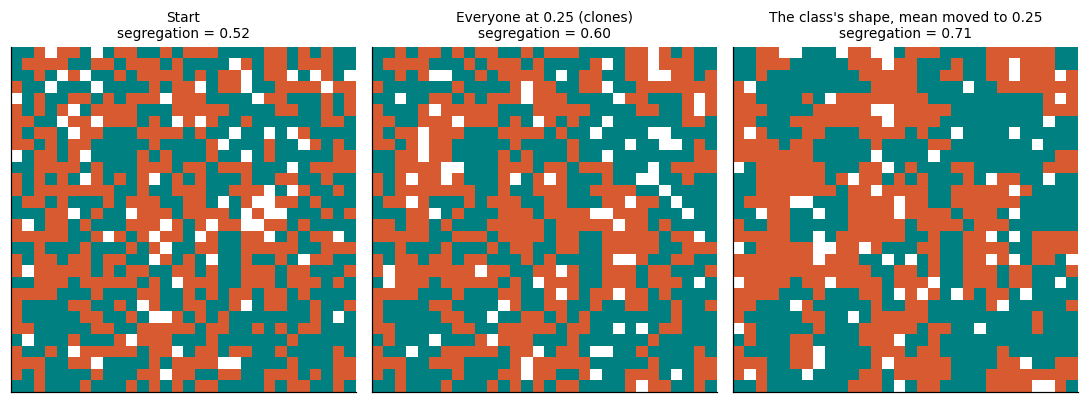

In [20]:
def class_like(mean, spread, size, r):
    # Thresholds with the class's shape, moved to `mean` and stretched by `spread`.
    draws = r.choice(class_thresholds, size=size)
    return np.clip(mean + spread * (draws - class_thresholds.mean()), 0, 1)

start = new_city(seed=2)
fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
show_city(start, "Start", ax[0])
show_city(run_city(start, class_like(0.25, 0, start.shape, np.random.default_rng(7)), seed=2), "Everyone at 0.25 (clones)", ax[1])
show_city(run_city(start, class_like(0.25, 1, start.shape, np.random.default_rng(7)), seed=2), "The class's shape, mean moved to 0.25", ax[2])
plt.tight_layout()

**How to read it.** The same start, two finished cities, same mean threshold of 0.25. Clones at 0.25 barely segregate: 0.25 is below the Monte Carlo seminar's tipping range, so an average household is content almost anywhere. The class's shape around the same mean segregates visibly: a demanding minority keeps moving, clusters form behind it, and the easy-going majority, once inside a cluster, has no reason to leave. (Try the slider: at means well above the tipping range the effect reverses a little, because some households are now tolerant enough to stay in mixed streets.)

> **The message of this model.** Segregation can set in *before* the average household's threshold says it should. Heterogeneity is not noise around the mean: it is what starts the process. A model that averages people away misses the onset, and reports a mixed city where the real one is sorting itself.

### ▶ Try it
Two pictures of the same city, before and after households have moved; the number under each is the segregation measure.

| Parameter | What it means | What to watch |
|---|---|---|
| Mean threshold | The average household's demand, moved without changing the class's shape | With Spread at 0, find the smallest mean at which the city segregates: that is the clones' tipping point from the Monte Carlo seminar |
| Spread × | How much households differ around that mean: 0 = clones, 1 = the class's shape, 2 = twice as varied | Set the mean just *below* the clones' tipping point and raise the spread: segregation appears that the clones never showed. Set it well above and raise the spread: segregation eases |
| Seed | Which random city and which random moves | One run is one draw; change the seed before believing any single picture |

In [21]:
@interact(mean=FloatSlider(value=round(float(class_thresholds.mean()), 2), min=0.05, max=0.6, step=0.05, description="Mean threshold"),
          spread=FloatSlider(value=1.0, min=0.0, max=2.0, step=0.25, description="Spread ×"),
          seed=IntSlider(value=1, min=0, max=10, description="Seed"))
def spread_city(mean, spread, seed):
    thr = class_like(mean, spread, (30, 30), np.random.default_rng(seed + 100))
    start = new_city(size=30, seed=seed); end = run_city(start, thr, seed=seed)
    fig, ax = plt.subplots(1, 2, figsize=(6.5, 3.2)); show_city(start, "Start", ax[0]); show_city(end, f"mean {mean:.2f}, spread × {spread}", ax[1]); plt.tight_layout()

interactive(children=(FloatSlider(value=0.35, description='Mean threshold', max=0.6, min=0.05, step=0.05), Flo…

## 5.2 The fare norm as a cascade

Now the main model. Imagine 5,000 passengers, each with a threshold from Stop 2: the share of *others* dodging at which this person would dodge too. The model runs in rounds. At the start some share is dodging (zero, unless we impose a shock). In each round every passenger looks at the current share, and dodges in the next round if that share is at or above their threshold, otherwise pays. The new share is simply the proportion of passengers whose threshold the old share reached. Repeat until the share stops changing. That is Granovetter's crowd from the Monte Carlo seminar with Estonian thresholds in it.

One parameter from Stop 3 is added: the **inspection rate**, the share of trips on which tickets are checked. The survey was answered under some inspection regime; we take the experts' most likely value, 12%, as that regime, so at 12% the thresholds are as surveyed. If inspections become rarer, every threshold drops; if they become more frequent, every threshold rises: effective threshold = threshold + weight × (inspection − 12%). The weight (how many points of threshold one point of inspection is worth) is a structural assumption with no data behind it, which is why it is a slider in 5.3. The rule is deliberately the simplest possible; what matters here is what the *distribution* of thresholds does inside it.

A worked round, with the linear rule and 2011 answers: 2.2% of people have a threshold of exactly 0 (they answered "always justifiable"), so from a quiet start they dodge in round 1. The next lowest thresholds are the 9s, at 0.11. A share of 2.2% does not reach 0.11, so nobody else joins, and the cascade stops at 2.2%: the sparks are there, but the ladder has a missing rung right above them.

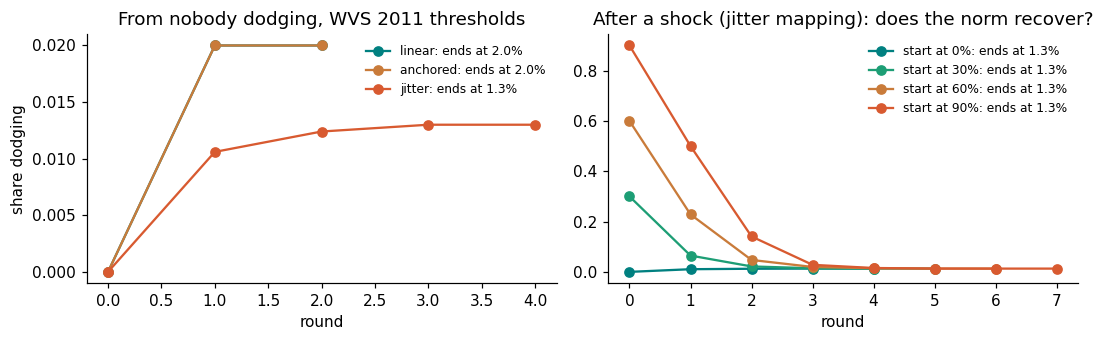

In [22]:
def cascade(thresholds, start_share=0.0, inspection=0.12, weight=7.0, reference=0.12, max_rounds=100):
    '''Share of dodgers round by round. Effective threshold = threshold + weight * (inspection - reference):
    at the reference inspection rate (the regime the survey was answered under) thresholds are as surveyed;
    rarer inspections lower every threshold, more frequent ones raise it.'''
    t = thresholds + weight * (inspection - reference)
    share = start_share; history = [share]
    for _ in range(max_rounds):
        new = (t <= share).mean()
        history.append(new)
        if new == share: break
        share = new
    return np.array(history)

r_people = np.random.default_rng(3)                                   # one generator for the people ...
answers = synthetic_respondents("avoiding_fare", 2011, 5000, r_people)
r_map = np.random.default_rng(4)                                      # ... and a different one for the mapping's jitter
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for m, colour in zip(["linear", "anchored", "jitter"], [TEAL, AMBER, CORAL]):
    h = cascade(to_threshold(answers, m, r_map))
    ax[0].plot(h, "o-", color=colour, label=f"{m}: ends at {h[-1]:.1%}")
ax[0].set_xlabel("round"); ax[0].set_ylabel("share dodging"); ax[0].set_title("From nobody dodging, WVS 2011 thresholds"); ax[0].legend(frameon=False, fontsize=8)

t = to_threshold(answers, "jitter", np.random.default_rng(4))
for s0, colour in zip([0.0, 0.3, 0.6, 0.9], [TEAL, GREEN, AMBER, CORAL]):
    h = cascade(t, start_share=s0); ax[1].plot(h, "o-", color=colour, label=f"start at {s0:.0%}: ends at {h[-1]:.1%}")
ax[1].set_xlabel("round"); ax[1].set_title("After a shock (jitter mapping): does the norm recover?"); ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()

**How to read it.** In both panels the horizontal axis is the round and the vertical axis the share of the crowd dodging after that round; a curve stops when the share no longer changes. Left: from nobody dodging, under the three rules. Each curve rises to a few per cent and stops: the sparks dodge, nobody's threshold is low enough to be reached by the sparks alone, and the cascade dies. The norm holds, and that is a finding: it agrees with what one sees on Estonian buses, and it was produced by a model whose only inputs were a survey item and a mapping. Right: the same crowd (jitter rule) after a shock, as if a strike week had left 30%, 60% or 90% travelling without tickets. In round 1 only those whose threshold the shock reaches keep dodging (from 90%, about half); their share reaches fewer thresholds, so fewer dodge in round 2; and within a few rounds the crowd is back at the same 1.3% it reaches from a quiet start. The norm is **self-correcting**, because most people's thresholds sit far above any level the sparks can hold.

> **The message of this figure.** The thresholds in it are the distributions built at Stop 2: the same 2011 answers through each rule. Left: the norm holds under *every* rule, so at this setting the result does not depend on the translation uncertainty of Stop 4. The level it settles at is roughly the sparks, because the ladder has a gap above them. Right: the norm self-corrects after any shock, which is what Stop 1's strain picture could not show, because there each person was judged alone; here people react to each other round by round. **Conditional on one structural assumption**: passengers have no memory. Each round they decide afresh. A rule with habit in it (once you have dodged, your threshold drops) would recover more slowly or not at all. That is structural uncertainty in the sense of Stop 4, and it must be reported with the result (Stop 6).

## 5.3 Where it tips, and why the average citizen never tells you

Now make dodging gradually easier and watch where the self-correction fails. The cell below subtracts the same amount, the *shift*, from every threshold (a threshold that falls below 0 becomes 0: that person now dodges regardless), runs the cascade from a quiet start, records the final share, and repeats for shifts from 0 to 0.8. Rarer inspections, free-riding becoming fashionable, or a collapse in enforcement would all act like this shift. It does the sweep twice: once with each person's own threshold, once with every person given the *average* threshold.

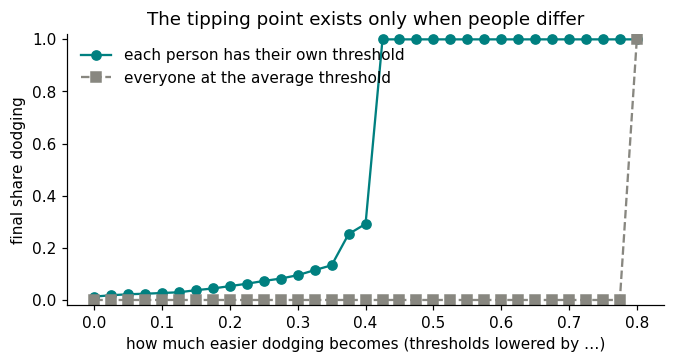

In [23]:
shifts = np.linspace(0, 0.8, 33)
def final_share(t, shift, start=0.0):
    return cascade(np.clip(t - shift, 0, 2), start_share=start)[-1]

t_people = to_threshold(answers, "jitter", np.random.default_rng(4))
t_clones = np.full_like(t_people, np.clip(t_people, 0, 1).mean())

plt.plot(shifts, [final_share(t_people, s) for s in shifts], "o-", color=TEAL, label="each person has their own threshold")
plt.plot(shifts, [final_share(t_clones, s) for s in shifts], "s--", color=GRAY, label="everyone at the average threshold")
plt.xlabel("how much easier dodging becomes (thresholds lowered by …)"); plt.ylabel("final share dodging")
plt.title("The tipping point exists only when people differ"); plt.legend(frameon=False); plt.ylim(-0.02, 1.02);

**How each point was made.** Take one value on the horizontal axis, say 0.3. Subtract 0.3 from every one of the 5,000 thresholds. Run the whole cascade of 5.2 from a quiet start until it settles. Plot the share dodging at the end: the same number that the legend of the previous figure called "ends at 1.3%". Then move to the next value and repeat. So each point is one complete run of the previous figure's kind, compressed to its last frame, and the vertical axis here is the same "final share dodging" as the end of every curve there and as the bars of the next figure. The horizontal axis is not a threshold: it is how far *all* thresholds have been moved.

**How to read it.** Teal, each person with their own threshold: the final share creeps up as the shift grows, because each step turns a few more people into sparks and brings the next rung of the ladder within reach; around a shift of 0.4 the rungs become continuous and the cascade runs to the whole crowd. That is the **tipping point**, and it is preceded by a visible rise, which is a warning sign a policymaker could watch. Grey, everyone at the average threshold (about 0.78): nothing at all until the shift reaches 0.78, then the grey curve also runs to 1.0, everyone at once, because 5,000 identical people all cross the line in the same round. **What it means for us:** the clone model puts the collapse in the wrong place (0.78 rather than 0.4) and removes the warning. The tipping point exists, and sits where it sits, only because people differ; a model that averages them away cannot see it.

### ▶ Try it
**How to read it.** Horizontal axis: rounds of the cascade. Vertical: the share of the crowd dodging after each round. The curve stops when nothing changes any more; the title gives the final share and the number of rounds. Grey means you have replaced the crowd by clones of the average citizen.

| Parameter | What it means | What to watch |
|---|---|---|
| Thresholds from | 1996 or 2011 WVS answers | 1996 had fewer "never" and more "always": the norm was weaker and tips earlier |
| Mapping | Which rule turned the scale into thresholds | Near the tipping point the rule decides which side you land on; far from it, it hardly matters |
| Inspection rate | The share of trips checked; 12% is the regime the survey was answered under, so at 12% the thresholds are as surveyed | Lower it step by step and find the value at which the final share jumps: that is the tipping point for this crowd. Raise it and the norm only gets safer |
| Its effect on thresholds | How many points of threshold one point of inspection is worth (effective threshold = threshold + weight × (inspection − 12%)) | A structural assumption with no data behind it. Change it and the tipping point moves; that is structural uncertainty made visible |
| Start share | A shock: the share already dodging at round 0 | Below the tipping point the curve falls back to the same low level from any start; above it, it rises from any start |
| Use the average citizen instead | Every person gets the mean threshold | The curve becomes flat at 0 or jumps to 1 with nothing in between, and the tipping point you found is gone. A population of clones has no sparks and no ladder |

Task: find the inspection rate at which the norm collapses for the 2011 crowd under the jitter rule. Then switch to the anchored rule and look again. Then turn on the average-citizen toggle and look a third time.

In [24]:
@interact(year=Dropdown(options=[1996, 2011], value=2011, description="Thresholds from"),
          mapping=Dropdown(options=["linear", "anchored", "jitter", "calibrated"], value="jitter", description="Mapping"),
          inspection=FloatSlider(value=0.12, min=0.01, max=0.5, step=0.01, description="Inspection rate"),
          weight=FloatSlider(value=7.0, min=0, max=12, step=0.5, description="Its effect on thresholds"),
          shock=FloatSlider(value=0.0, min=0, max=1, step=0.05, description="Start share"),
          average_citizen=Checkbox(value=False, description="Use the average citizen instead"))
def fare_model(year, mapping, inspection, weight, shock, average_citizen):
    a = synthetic_respondents("avoiding_fare", year, 5000, np.random.default_rng(3))
    t = to_threshold(a, mapping, np.random.default_rng(4))
    if average_citizen: t = np.full_like(t, np.clip(t, 0, 1).mean())
    h = cascade(np.clip(t, 0, 2), start_share=shock, inspection=inspection, weight=weight)
    plt.plot(h, "o-", color=GRAY if average_citizen else TEAL); plt.ylim(-0.02, 1.02)
    plt.xlabel("round"); plt.ylabel("share dodging")
    plt.title(f"{'AVERAGE CITIZEN' if average_citizen else 'real spread'} · {year} {mapping}: ends at {h[-1]:.1%} after {len(h) - 1} rounds")

interactive(children=(Dropdown(description='Thresholds from', index=1, options=(1996, 2011), value=2011), Drop…

## 5.4 Which uncertainty moves the outcome? Sensitivity in one picture

We have four inputs we are unsure about: the mapping (Stop 2), the survey year (which crowd), the inspection rate (Stop 3's experts said 5% to 40%), and the survey size. The honest question is which of them changes the model's answer most, because that is the one worth measuring better. The cell below does the simplest sensitivity analysis, *one at a time*:

1. Fix a base setting: 2011 answers, jitter rule, inspection 12%, a crowd of 1,503 (one synthetic respondent per real one).
2. For the mapping bar, run the cascade three times, once per rule, everything else at base; note the three final shares. For the year bar, twice (1996, 2011). For the inspection bar, eight times, at 5%, 10%, … 40%. For the survey-size bar, three times, with crowds of 29, 200 and 1,503.
3. Each bar runs from the smallest to the largest final share that input produced.

The quantity on the horizontal axis is the same "final share dodging" as the last frame of 5.2 and the vertical axis of 5.3; every run here is one point of that kind.

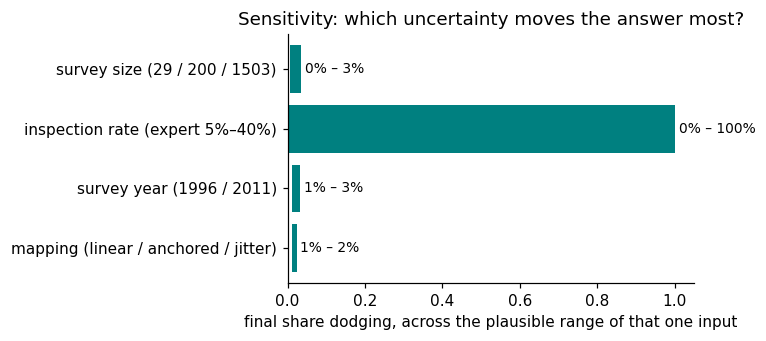

In [25]:
base = dict(year=2011, mapping="jitter", inspection=0.12, n=1503)
def run_with(**kw):
    p = {**base, **kw}; r = np.random.default_rng(5)
    a = synthetic_respondents("avoiding_fare", p["year"], p["n"], r)
    t = to_threshold(a, p["mapping"], r)
    return cascade(np.clip(t, 0, 2), inspection=p["inspection"], weight=7.0)[-1]

results = {
    "mapping (linear / anchored / jitter)": [run_with(mapping=m) for m in ["linear", "anchored", "jitter"]],
    "survey year (1996 / 2011)":            [run_with(year=y) for y in [1996, 2011]],
    "inspection rate (expert 5%–40%)":      [run_with(inspection=x) for x in np.linspace(0.05, 0.40, 8)],
    "survey size (29 / 200 / 1503)":        [run_with(n=n) for n in [29, 200, 1503]],
}
for k, v in results.items():
    lo, hi = min(v), max(v)
    plt.barh(k, hi - lo, left=lo, color=TEAL); plt.text(hi + 0.01, k, f"{lo:.0%} – {hi:.0%}", va="center", fontsize=9)
plt.xlabel("final share dodging, across the plausible range of that one input"); plt.xlim(0, 1.05)
plt.title("Sensitivity: which uncertainty moves the answer most?"); plt.tight_layout()

**How to read it.** One bar per uncertain input; the horizontal axis is the final share dodging; the bar spans the range of answers that input alone can produce. A short bar means that however that input turns out within its plausible range, the model's answer barely moves; a long bar means the answer depends on it. Here the inspection bar runs to 100%: at the experts' low end, 5%, every threshold is lowered by 7 × (0.12 − 0.05) = 0.49, which is past the tipping point of 5.3; at the high end thresholds rise and the norm is safer than surveyed. So the plausible range of one input straddles the collapse. The mapping bar is short: at this setting the three rules land on the same side of the tipping point, and the survey size and year matter about as little.

**What it means for us:** at these settings the inspection rate is the uncertainty worth money, and a better survey or a better mapping would be wasted effort. That is not a general truth about mappings; it is a truth about *this* model at *this* setting. Change `inspection` in `base` to a value near the tipping point and run the cell again: there the rules land on different sides of the tip and the mapping bar becomes the longest. Sensitivity analysis has to be redone whenever the setting changes; that is why it is a habit, not a step.

**Where is the translation recipe here?**

| | |
|---|---|
| 1 · The material | The threshold distributions from Stop 2, the inspection distribution from Stop 3, and the Monte Carlo seminar's two models. |
| 2 · The rule | One changed line: a draw per agent from the distribution, instead of one number for everyone. |
| 3 · The distribution | Across runs: the band of outcomes per rule, per year, per inspection rate; the sensitivity bars. |
| Uncertainty carried forward | Whichever source the sensitivity bars show to be largest at the setting you report; here the inspection rate, because its range crosses the tipping point. |
| 4 · The use | The result a project would report: whether the norm holds, where it tips, and which assumption that depends on. |

*What this stop adds to the argument:* with distributions in place of numbers, the model acquires behaviour nobody wrote into it: self-correction, a tipping point, and sensitivity to how people differ. Replace the distribution by its mean and all of it disappears.

# Stop 6 · Reporting, and your project

## 6.1 What to report

Every number that entered the model today was a translation, and every translation had a choice and an uncertainty. A reader of your project needs to see them. For every translated input, report:

* **The material**: what was measured, on what level of measurement, from whom, how many. *WVS "justifiable" item, ordinal 1–10, Estonia 2011, n = 1,503.*
* **The rule** that turned it into a number, and the alternatives you did not choose. *Jitter; linear and anchored also run.*
* **The distribution** the model received, not a single number. *A threshold per agent; 22% beyond reach; 1% sparks.*
* **Which uncertainty dominates** at the setting you report, and which kind it is. *Inspection rate (epistemic, from two experts) dominates; the rule barely matters here.*
* **The structural assumptions** the result is conditional on. *Passengers without memory; the 2011 meaning of the item, before free fares.*
* **What would change the conclusion.** *An inspection rate below about 7%; a rule with habit in it.*

The last line is the one readers remember. It is also the one that tells you what to measure next.

## 6.2 The honesty rules, extended

The Monte Carlo seminar ended with five habits: garbage in, gospel out; report the spread; use enough runs; fix the seed; a model is not the world. This seminar adds two:

6. **Report the mapping you did not choose.** If a different defensible translation gives a different answer, say so, and show both. A result that survives all four rules is a result; one that holds under one rule is a hypothesis about the rule.
7. **Never collapse a distribution into its mean before the model runs.** Give every agent its own draw. The average citizen does not exist, and a model made of average citizens cannot tip, cascade or segregate.

## 6.3 Where this reappears in the course

The same move, qualitative material into a distribution with a stated mapping, appears under several names in the coming weeks: the **impact and interest scales** for stakeholders are a pseudo-quantification of judgement; the **vulnerability** scores in the risk and crisis simulations are another; the **perceived situational awareness** metrics are Likert items awaiting a mapping; **synthetic data** is drawing imaginary respondents from exactly the distributions built here (we did it in every cell that said `synthetic_respondents`); and the **language-model** seminar automates the coding of Stop 3. When you meet each one, look for the four steps of the recipe: the material, the rule, the distribution, and the use.

## 6.4 For your project

Before you write a line of model code, write the list of 6.1 for every input. For each ask: is this an attribute, a rule, a parameter or an initial state? What level of measurement is the source? Can I design the question so that it answers in the model's units (as Q4 and Q5 did)? Which rule am I choosing, and what is the alternative? Which of the four uncertainties dominates? Then run the model as a Monte Carlo experiment, as in the last seminar, and report the band, not the number.

# References

* Bicchieri, C. (2017). *Norms in the Wild: How to Diagnose, Measure, and Change Social Norms.* Oxford University Press.
* Clark, W. A. V. (1991). Residential preferences and neighborhood racial segregation: A test of the Schelling segregation model. *Demography*, 28(1), 1–19.
* Farley, R., Schuman, H., Bianchi, S., Colasanto, D., & Hatchett, S. (1978). “Chocolate city, vanilla suburbs”: Will the trend toward racially separate communities continue? *Social Science Research*, 7(4), 319–344.
* Granovetter, M. (1978). Threshold models of collective behavior. *American Journal of Sociology*, 83(6), 1420–1443.
* Inglehart, R., Haerpfer, C., Moreno, A., Welzel, C., Kizilova, K., Diez-Medrano, J., Lagos, M., Norris, P., Ponarin, E., & Puranen, B. (eds.) (2014). *World Values Survey: Round Three (1995–1998) and Round Six (2010–2014), Country-Pooled Datafiles.* Madrid: JD Systems Institute. Estonia 1996 (n = 1,021) and 2011 (n = 1,533). <https://www.worldvaluessurvey.org/>
* Lazarsfeld, P. F. (1958). Evidence and inference in social research. *Daedalus*, 87(4), 99–130.
* O'Hagan, A., Buck, C. E., Daneshkhah, A., Eiser, J. R., Garthwaite, P. H., Jenkinson, D. J., Oakley, J. E., & Rakow, T. (2006). *Uncertain Judgements: Eliciting Experts' Probabilities.* Wiley.
* Schelling, T. C. (1971). Dynamic models of segregation. *Journal of Mathematical Sociology*, 1(2), 143–186.
* Stevens, S. S. (1946). On the theory of scales of measurement. *Science*, 103(2684), 677–680.